# 28 Prognose-LSTM: ein Wächter für neue Veränderungen

Teil 6: Lernende Modelle

**Worum es geht**
- Notebook 27 zeigt: Ein LSTM (neuronales Netz für Zeitreihen mit Gedächtnis) kann das Verhalten einer Station lernen. Hier wird daraus ein Wächter.
- Das Netz sagt jeden Tag Rücklauf und Durchfluss einer Station vorher, aus der letzten Woche, dem Wetter und der Vorlauftemperatur des Netzes. Weicht die Station deutlich und anhaltend ab, gibt es eine Warnung.
- Notebook 27 und 29 suchen bestehende Fehler aus den Begehungen. Der Wächter sucht neue Veränderungen und vergleicht jede Station mit sich selbst: Ein schon immer undichtes Ventil ist für ihn normal, eines, das ab morgen offen steht, nicht.
- Der Weg dorthin in Versuchen (Abschnitte 2 und 3): Wie viele Tage Vorgeschichte braucht eine Vorhersage, was bringt ein LSTM gegenüber dem 7-Tage-Mittel, und wie weit kommt ein einfacher Wächter ohne Netz?
- Vorgabe der Betreuung wie in Notebook 27: Gelernt wird nur auf HAST (Hausanschlussstationen) mit Begehung, überwacht werden alle Zähler. Zum Vergleich läuft dasselbe Netz auf allen HAST.

**Daten**
- liest: `data/processed/modell_stunden.parquet`, `data/processed/modell_labels.csv`, für die Vorversuche die Zählerreihen `data/processed/real_meters/` aus Notebook 00 und, falls vorhanden, die Gewichte des Vorhersage-LSTM aus Notebook 27 (`notebooks/models/vorversuche/`)
- schreibt: `data/processed/prognose_tage.csv` (Abweichung, z-Werte, Warnungen und Alarme je Zähler und Tag), mit `SELBST_TRAINIEREN = True` auch Modellgewichte in `notebooks/models/`, Abbildungen nach `docs/assets/modelle/`
- vorher ausführen: Notebook 25 und 27 (Abschnitt 2 lädt das Ein-Tag-Netz aus Notebook 27)
- Notebook 30 nutzt die Warnungen für den Vergleich mit dem Normalverhaltensmodell (Notebook 18).

**Code**
- Netz und Warnregel stehen im Notebook. Dieselbe Netzdefinition steht für den Betrieb in `src/prognose_waechter.py` (`netz`).

| Abschnitt | Inhalt |
|---|---|
| 1 | Ausgangslage und Setup |
| 2 | Wie viele Tage Vorgeschichte? Fensterlänge und drei Ideen für das LSTM |
| 3 | Ein einfacher Wächter ohne Netz |
| 4 bis 13 | Der Wächter: Daten, Netz, Training, Vorhersage, Warnung, eingerechnete Fehler, Alarme, Begehungen, Haus oder Netz, Speichern |

## 1 Ausgangslage und Setup

### 1.1 Was vorher versucht wurde

- Einen Wächter, der Veränderungen meldet, gab es im Projekt schon mehrfach.
- CUSUM = Summe der Abweichungen, schlägt an, wenn sie zu groß wird.

| Versuch | wo | Ergebnis | Folgerung |
|---|---|---|---|
| Unüberwachte Scores auf Stundenwerten (Isolation Forest, PCA, K-Means-Distanz, saisonale 24-h-Abweichung) | Gesamtpipeline aus dem August (nicht im Abgabestand) | von 10 Ereignissen höchstens 2 gefunden; PCA mit 19 Fehlalarm-Läufen | ohne Erwartungswert weiß ein Score nicht, was für diese Station bei diesem Wetter normal ist |
| Kennlinienmonitor | [Notebook 13](../4_stationsbilder/13_kennlinienmonitor.ipynb) | etwa 1,3-fach über Zufall, knapp 5 Alarme je Station und Jahr | eine Erwartung je Station hilft, die Alarmmenge ist hoch |
| Normalverhaltensmodell (Kennlinie gegen Außentemperatur, CUSUM) | [Notebook 18](../5_monitoring/18_normalverhalten.ipynb) | Alarme treffen Begehungen zu 70 % gegen 53 % ohne Begehung | stabil im Winter, im Sommer blind; Vergleich in [Notebook 30](30_waechtervergleich.ipynb) |
| Prognose-LSTM mit Wetter, eigenem Vorlauf und den 4 Nachbarn im Leitungsnetz | lokale Vorarbeit | Rücklauf 3,9 K daneben gegen 5,4 K „wie gestern“; Nachbarn und Wetter ändern fast nichts (3,86–3,92 K); bei der damaligen Schwelle 28 % Fehlalarme | Nachbarn weglassen, Schwelle an einer festen Fehlalarmrate wählen |
| Zusätzliche Tagesform-Merkmale (Abweichung unter Last, Sprunghaftigkeit) | lokale Vorarbeit | mehr Treffer, aber mehr Fehlalarme (bei z ≥ 3: 29 % auf 49 %) | kein echter Gewinn, weggelassen |

Was hier anders ist:
- Stundenwerte statt Tageswerte. Der Wächter sieht Tagesverlauf und Nacht, also genau dort, wo ein offenes Ventil auffällt.
- Die Schwelle wird an einer festen Fehlalarmrate gewählt, nicht nach Gefühl.
- Neu ist ein Faktor je Jahreszeit, weil die Stationen im Winter vermutlich stärker schwanken als im Sommer (Ergebnis in Abschnitt 6).
- Gezählt wird wie beim Normalverhaltensmodell: ein Alarm je Veränderung, nicht einer je Tag. So lassen sich beide Wächter in Notebook 30 auf gleicher Grundlage vergleichen.

### 1.2 Setup

- Lädt PyTorch und legt Pfade und Festlegungen fest.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
LERNEN_BIS = pd.Timestamp("2024-06-01")    #danach: Sommer 2024 als saubere Testzeit vor den Begehungen
VORGESCHICHTE = 7                           #Tage
HEIZGRENZE_C = 15.0                         #Tagesmittel darunter = Heiztag (wie in Notebook 15)
SELBST_TRAINIEREN = False                   #True: alle Netze neu lernen, sonst Gewichte laden (wie Notebook 27)
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


- Aufbau wie in Notebook 27, mit drei neuen Festlegungen.
- `LERNEN_BIS`: Das Netz lernt nur bis Ende Mai 2024. Der Sommer 2024 liegt noch vor den Begehungen und ist eine saubere Testzeit: Jede Warnung dort ist ein Fehlalarm, und eingerechnete Fehler lassen sich an ungestörten Tagen prüfen.
- `VORGESCHICHTE`: Das Netz sieht jeweils die letzten 7 Tage.
- `HEIZGRENZE_C`: Ein Tag mit Tagesmittel unter 15 °C gilt als Heiztag, wie beim Normalverhaltensmodell (Notebook 18).
- `SELBST_TRAINIEREN` wirkt wie in Notebook 27: Mit `False` werden alle Netze aus `notebooks/models/` geladen, auch die der Vorversuche, mit `True` neu gelernt.

- Für die Vorversuche kommen dazu: der Ordner der Zählerreihen, ein Ordner für Abbildungen und einer für die Gewichte der Vorversuche. `cudnn.deterministic` sorgt dafür, dass sie bei jedem Lauf dieselben Zahlen liefern.

In [2]:
import copy
import sys

from scipy.stats import binomtest

sys.path.insert(0, str(ROOT))
from src.weather import load_outdoor_temperature

METER_DIR = PROCESSED / "real_meters"
BILDER = ROOT / "docs" / "assets" / "modelle"
BILDER.mkdir(parents=True, exist_ok=True)
VORVERSUCHE = MODELLE / "vorversuche"
VORVERSUCHE.mkdir(parents=True, exist_ok=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
geraet = GERAET

def gewichte_laden(datei):
    #nur mit SELBST_TRAINIEREN = False: gespeicherte Gewichte lesen statt lernen
    if not datei.exists():
        raise FileNotFoundError(f"{datei.relative_to(ROOT)} fehlt. Die Gewichte nach notebooks/models/ kopieren "
                                "oder oben SELBST_TRAINIEREN = True setzen.")
    return torch.load(datei, map_location=GERAET)

## 2 Wie viele Tage Vorgeschichte?

- Ein Wächter vergleicht jeden Tag mit einer Erwartung. Die einfachste Erwartung ist das Mittel der letzten Tage. Wie viele Tage dafür am besten sind, ist die erste Frage.
- Dafür dieselbe Aufbereitung wie in Notebook 27, Abschnitt 2 und 3: vollständige Tage der begangenen Stationen ab November 2022 und vor der Begehung, vier Kanäle (Rücklauf, Durchfluss, Vorlauf, Außentemperatur), Aufteilung nach der Zeit.

In [3]:
kanaele = {
    "ruecklauf": "Return temperature (°C)",
    "durchfluss": "Volume flow (l/h)",
    "vorlauf": "Flow temperature (°C)",
}

In [4]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
labels["ende"] = labels["erste_begehung"].fillna(pd.Timestamp("2024-09-01")).clip(upper=pd.Timestamp("2024-09-01"))

In [5]:
from src.weather import load_outdoor_temperature

wetter = load_outdoor_temperature("2022-11-01", "2024-09-01")
wetter["tag"] = wetter["timestamp"].dt.date
wetter["stunde"] = wetter["timestamp"].dt.hour
aussen = wetter.pivot(index="tag", columns="stunde", values="t_out")

In [6]:
X_liste = []
info_liste = []

for z, ende in zip(labels["zaehler"], labels["ende"]):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < ende)]
    if len(d) == 0:
        continue
    d["tag"] = d["Timestamp"].dt.date
    d["stunde"] = d["Timestamp"].dt.hour

    tabellen = {}
    for name, spalte in kanaele.items():
        tabellen[name] = d.pivot(index="tag", columns="stunde", values=spalte)
    tabellen["aussen"] = aussen

    alle = pd.concat(tabellen, axis=1).dropna()
    X_liste.append(alle.values.reshape(len(alle), 4, 24).transpose(0, 2, 1))
    info_liste.append(pd.DataFrame({"zaehler": z, "tag": alle.index}))

In [7]:
import numpy as np

X_alle = np.concatenate(X_liste)
info = pd.concat(info_liste, ignore_index=True)
X_alle.shape

(24684, 24, 4)

In [8]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = pd.to_datetime(info["tag"])

In [9]:
info["tag"] = pd.to_datetime(info["tag"])
info["woche"] = info["tag"].dt.to_period("W").astype(str)

In [10]:
test = info["tag"] >= "2024-06-01"

wochen = info.loc[~test, "woche"].unique()
np.random.seed(0)
val_wochen = np.random.choice(wochen, size=int(0.1 * len(wochen)), replace=False)

val = info["woche"].isin(val_wochen) & ~test
train = ~test & ~val

In [11]:
train.sum(), val.sum(), test.sum()

(np.int64(18689), np.int64(1511), np.int64(4484))

### 2.1 Fensterlänge der Messlatte

- Statt nur 7 Tage verschiedene Fenster: das Mittel der letzten 1, 3, 7, 14 und 30 Tage als Vorhersage für den Rücklauf von morgen. Fenster 1 ist „wie gestern“.
- Ausgesucht wird auf der Validierung, nicht im Test. Sonst wäre es eine Auswahl nach dem Ergebnis.

In [12]:
fenster = [1, 3, 7, 14, 30]
vorhersagen = {}
for f in fenster:
    vorhersagen[f] = np.full((len(info), 24), np.nan)

for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns="zaehler").asfreq("D")
    for f in fenster:
        w = g.rolling(f).mean().shift(1)
        vorhersagen[f][gruppe.index] = w.loc[gruppe["tag"]].values

In [13]:
alle_da = np.ones(len(info), dtype=bool)
for f in fenster:
    alle_da = alle_da & ~np.isnan(vorhersagen[f]).any(axis=1)

wahr = X_alle[:, :, 0]
teil = alle_da & val.values
for f in fenster:
    print(f, "Tage:", np.abs(vorhersagen[f][teil] - wahr[teil]).mean().round(2))

1 Tage: 6.05
3 Tage: 5.38
7 Tage: 5.32
14 Tage: 5.52
30 Tage: 6.2


- Eine U-Form: Mit 1 Tag liegt die Vorhersage im Mittel 6,05 K daneben, mit 3 Tagen 5,38, mit 7 Tagen 5,32, mit 14 Tagen 5,52 und mit 30 Tagen 6,20 K.
- Zu kurz nimmt den Zufall von gestern mit, etwa ob die Station gerade getaktet hat. Zu lang nimmt das Wetter von vor Wochen mit.
- Am besten sind 7 Tage. Erst jetzt, nach der Wahl, einmal in den Test:

In [14]:
teil = alle_da & test.values
print("7 Tage im Test:", np.abs(vorhersagen[7][teil] - wahr[teil]).mean().round(2))
print("wie gestern im Test:", np.abs(vorhersagen[1][teil] - wahr[teil]).mean().round(2))

7 Tage im Test: 4.28
wie gestern im Test: 4.66


- Auch im Test, dem Sommer 2024, sind 7 Tage besser als „wie gestern“ (4,28 gegen 4,66 K).
- Deshalb sieht der Wächter jeweils die letzten 7 Tage, und das 7-Tage-Mittel ist die Messlatte, die das Netz schlagen muss.

### 2.2 Ein LSTM gegen das 7-Tage-Mittel

- Das Vorhersage-LSTM aus Notebook 27 (Abschnitt 4: ein Tag als Eingabe, 256 Gedächtniszahlen, Early Stopping) im Vergleich mit dem 7-Tage-Mittel.
- Dieselben Paare aus heute und morgen, dieselbe Skalierung aus dem Training, als fünfter Kanal die Außentemperatur von morgen.

In [15]:
class Vorhersage(torch.nn.Module):
    def __init__(self, kanaele, gedaechtnis):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=kanaele, hidden_size=gedaechtnis, batch_first=True)
        self.ausgang = torch.nn.Linear(gedaechtnis, 24)

    def forward(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.ausgang(h[-1])

In [16]:
naechster = info.groupby("zaehler")["tag"].shift(-1)
paar = (naechster - info["tag"]) == pd.Timedelta(days=1)
heute = np.where(paar)[0]
morgen = heute + 1

In [17]:
mittel = X_alle[train.values].mean(axis=(0, 1))
streuung = X_alle[train.values].std(axis=(0, 1))
X_s = (X_alle - mittel) / streuung

In [18]:
eingabe = np.concatenate([X_s[heute], X_s[morgen][:, :, 3:4]], axis=2)
ziel = X_s[morgen][:, :, 0]

ist_train = train.values[morgen]
ist_val = val.values[morgen]
ist_test = test.values[morgen]

eingabe.shape

(24236, 24, 5)

- Die Trainingsschleife als Funktion, damit sie nicht für jede Idee neu geschrieben werden muss. Sie macht dasselbe wie in Notebook 27: Adam, Lernrate 0,001, Stapel von 256, Early Stopping nach 20 Runden ohne Besserung. Mit `SELBST_TRAINIEREN = False` lädt sie stattdessen die gespeicherten Gewichte aus `datei`.

In [19]:
fehler = torch.nn.MSELoss()

In [20]:
def trainiere(x_tr, y_tr, x_va, y_va, datei):
    x_tr = torch.tensor(x_tr, dtype=torch.float32, device=geraet)
    y_tr = torch.tensor(y_tr, dtype=torch.float32, device=geraet)
    x_va = torch.tensor(x_va, dtype=torch.float32, device=geraet)
    y_va = torch.tensor(y_va, dtype=torch.float32, device=geraet)

    torch.manual_seed(0)
    modell = Vorhersage(kanaele=x_tr.shape[2], gedaechtnis=256).to(geraet)
    if not SELBST_TRAINIEREN:
        gespeichert = gewichte_laden(datei)
        modell.load_state_dict(gespeichert["gewichte"])
        print("geladen:", datei.name, "  beste Runde:", gespeichert["beste_runde"],
              "  Validierungsfehler:", round(gespeichert["bester_fehler"], 4))
        return modell

    optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        modell.train()
        reihenfolge = torch.randperm(len(x_tr), device=geraet)
        for start in range(0, len(x_tr), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell(x_tr[stapel]), y_tr[stapel])
            loss.backward()
            optimierer.step()

        modell.eval()
        with torch.no_grad():
            f_val = fehler(modell(x_va), y_va).item()
        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(modell.state_dict())
            beste_runde = runde
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    modell.load_state_dict(bester_stand)
    print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))
    torch.save({"gewichte": modell.state_dict(), "beste_runde": beste_runde, "bester_fehler": bester_fehler}, datei)
    return modell

In [21]:
def vorhersage(modell, x):
    ergebnis = []
    with torch.no_grad():
        for start in range(0, len(x), 2048):
            stueck = torch.tensor(x[start:start + 2048], dtype=torch.float32, device=geraet)
            ergebnis.append(modell(stueck).cpu().numpy())
    return np.concatenate(ergebnis)

- Das Netz für einen Tag wurde in Notebook 27 gelernt (Abschnitt 4.3) und wird hier nur geladen. Notebook 27 muss also vorher gelaufen sein, oder seine Gewichte liegen schon in `notebooks/models/vorversuche/`.

In [22]:
datei = VORVERSUCHE / "vorhersage_1tag.pt"
if not datei.exists():
    raise FileNotFoundError(f"{datei.relative_to(ROOT)} fehlt. Zuerst Notebook 27 ausführen "
                            "oder die Gewichte nach notebooks/models/ kopieren.")
modell = Vorhersage(kanaele=5, gedaechtnis=256).to(geraet)
modell.load_state_dict(torch.load(datei, map_location=geraet)["gewichte"])
print("geladen:", datei.name)

geladen: vorhersage_1tag.pt


In [23]:
x_val = torch.tensor(eingabe[ist_val], dtype=torch.float32, device=geraet)
x_test = torch.tensor(eingabe[ist_test], dtype=torch.float32, device=geraet)

with torch.no_grad():
    p_val = modell(x_val).cpu().numpy()
    p_test = modell(x_test).cpu().numpy()

In [24]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = info["tag"]

mittel7 = np.full((len(info), 24), np.nan)
for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7[gruppe.index] = w.loc[gruppe["tag"]].values

In [25]:
m7 = mittel7[morgen]
ok = ~np.isnan(m7).any(axis=1)
wahr = X_alle[morgen][:, :, 0]

for name, teil, p in [("Validierung", ist_val, p_val), ("Test", ist_test, p_test)]:
    o = ok[teil]
    lstm_grad = p[o] * streuung[0] + mittel[0]
    print(name, "LSTM:", np.abs(lstm_grad - wahr[teil][o]).mean().round(2),
          "  7 Tage:", np.abs(m7[teil][o] - wahr[teil][o]).mean().round(2))

Validierung LSTM: 5.07   7 Tage: 5.29
Test LSTM: 4.84   7 Tage: 4.28


- Auf der Validierung schlägt das LSTM das 7-Tage-Mittel knapp (5,07 gegen 5,29 K).
- Im Test, dem Sommer 2024, verliert es (4,84 gegen 4,28 K). Für einen Wächter, der jeden Tag vorhersagen soll, reicht das nicht.

In [26]:
p_1 = vorhersage(modell, eingabe) * streuung[0] + mittel[0]

### 2.3 Drei Ideen

1. Dem LSTM 7 Tage zeigen statt einem.
2. Nicht den Rücklauf selbst vorhersagen, sondern die Abweichung vom 7-Tage-Mittel.
3. Auf allen HAST lernen statt nur auf den begangenen.

**Idee 1: 7 Tage als Eingabe.** Statt nur heute bekommt das LSTM heute und die 6 Tage davor, also 168 Stunden hintereinander. `nummer` merkt sich, in welcher Zeile welcher Tag welcher Station steht:

In [27]:
nummer = {}
for i, (z, t) in enumerate(zip(info["zaehler"], info["tag"])):
    nummer[(z, t)] = i

reihen = []
for i in heute:
    z = info["zaehler"][i]
    t = info["tag"][i]
    reihen.append([nummer.get((z, t - pd.Timedelta(days=k)), -1) for k in range(6, -1, -1)])
reihen = np.array(reihen)

hat7 = (reihen >= 0).all(axis=1)
hat7.mean(), (hat7 == ok).all()

(np.float64(0.9065027232216537), np.True_)

- Bei 91 % der Paare gibt es alle 6 Vortage. Das sind genau die Tage, an denen es auch das 7-Tage-Mittel gibt. Fehlt ein Vortag, steht dort −1, diese Paare fallen weg.
- Die 7 Tage werden hintereinandergehängt, 168 Stunden mit 4 Kanälen:

In [28]:
eingabe7 = X_s[np.where(reihen >= 0, reihen, 0)].reshape(len(heute), 7 * 24, 4)
eingabe7.shape

(24236, 168, 4)

In [29]:
modell7 = trainiere(eingabe7[ist_train & hat7], ziel[ist_train & hat7], eingabe7[ist_val & hat7], ziel[ist_val & hat7],
                    VORVERSUCHE / "vorhersage_7tage.pt")

geladen: vorhersage_7tage.pt   beste Runde: 90   Validierungsfehler: 0.2096


In [30]:
p_7 = vorhersage(modell7, eingabe7) * streuung[0] + mittel[0]
p_7[~hat7] = np.nan

**Idee 2: Abweichung vom 7-Tage-Mittel.** Das LSTM bekommt das 7-Tage-Mittel als sechsten Kanal und soll nur noch vorhersagen, wie weit morgen davon abweicht. Lernt es nichts, kommt genau die Messlatte heraus.

In [31]:
m7_s = (np.nan_to_num(m7) - mittel[0]) / streuung[0]
eingabe_r = np.concatenate([eingabe, m7_s[:, :, None]], axis=2)
ziel_r = ziel - m7_s

In [32]:
modell_r = trainiere(eingabe_r[ist_train & ok], ziel_r[ist_train & ok], eingabe_r[ist_val & ok], ziel_r[ist_val & ok],
                     VORVERSUCHE / "vorhersage_abweichung.pt")

geladen: vorhersage_abweichung.pt   beste Runde: 32   Validierungsfehler: 0.2208


In [33]:
p_r = (vorhersage(modell_r, eingabe_r) + m7_s) * streuung[0] + mittel[0]
p_r[~ok] = np.nan

**Idee 3: Auf allen HAST lernen.** Für eine Vorhersage braucht man keine Labels, also könnte man auch alle Zähler nehmen. Gleiche Validierungswochen, gleicher Test, gleiche Skalierung wie bei den begangenen HAST, damit der Vergleich fair ist:

In [34]:
from src.weather import load_outdoor_temperature

labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
labels["ende"] = labels["erste_begehung"].fillna(pd.Timestamp("2024-09-01")).clip(upper=pd.Timestamp("2024-09-01"))
ende = dict(zip(labels["zaehler"], labels["ende"]))

wetter = load_outdoor_temperature("2022-11-01", "2024-09-01")
wetter["tag"] = wetter["timestamp"].dt.date
wetter["stunde"] = wetter["timestamp"].dt.hour
aussen = wetter.pivot(index="tag", columns="stunde", values="t_out")

kanaele = {
    "ruecklauf": "Return temperature (°C)",
    "durchfluss": "Volume flow (l/h)",
    "vorlauf": "Flow temperature (°C)",
}

In [35]:
X_liste = []
info_liste = []

for datei in sorted(METER_DIR.glob("*.csv")):
    z = int(datei.stem)
    d = pd.read_csv(datei, parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < ende.get(z, pd.Timestamp("2024-09-01")))]
    if len(d) == 0:
        continue
    d["tag"] = d["Timestamp"].dt.date
    d["stunde"] = d["Timestamp"].dt.hour

    tabellen = {}
    for name, spalte in kanaele.items():
        tabellen[name] = d.pivot(index="tag", columns="stunde", values=spalte)
    tabellen["aussen"] = aussen

    alle = pd.concat(tabellen, axis=1).dropna()
    if len(alle) == 0:
        continue
    X_liste.append(alle.values.reshape(len(alle), 4, 24).transpose(0, 2, 1))
    info_liste.append(pd.DataFrame({"zaehler": z, "tag": pd.to_datetime(alle.index)}))

X_hast = np.concatenate(X_liste)
info_hast = pd.concat(info_liste, ignore_index=True)
X_hast.shape, info_hast["zaehler"].nunique()

((41029, 24, 4), 91)

In [36]:
info_hast["woche"] = info_hast["tag"].dt.to_period("W").astype(str)
test_h = info_hast["tag"] >= "2024-06-01"
val_h = info_hast["woche"].isin(val_wochen) & ~test_h
train_h = ~test_h & ~val_h

naechster_h = info_hast.groupby("zaehler")["tag"].shift(-1)
heute_h = np.where((naechster_h - info_hast["tag"]) == pd.Timedelta(days=1))[0]
morgen_h = heute_h + 1

X_hast_s = (X_hast - mittel) / streuung
eingabe_h = np.concatenate([X_hast_s[heute_h], X_hast_s[morgen_h][:, :, 3:4]], axis=2)
ziel_h = X_hast_s[morgen_h][:, :, 0]
ist_train_h = train_h.values[morgen_h]
ist_train_h.sum()

np.int64(30619)

Gelernt wird auf allen HAST, das Early Stopping schaut auf dieselbe Validierung wie vorher (begangene HAST):

In [37]:
modell_h = trainiere(eingabe_h[ist_train_h], ziel_h[ist_train_h], eingabe[ist_val], ziel[ist_val],
                     VORVERSUCHE / "vorhersage_alle_hast.pt")

geladen: vorhersage_alle_hast.pt   beste Runde: 39   Validierungsfehler: 0.2168


In [38]:
p_h = vorhersage(modell_h, eingabe) * streuung[0] + mittel[0]

**Vergleich.** Alles auf denselben Tagen (mit 7-Tage-Mittel), getrennt nach Validierung, den Sommertagen der Validierung (Mai bis September) und Test:

In [39]:
monat = info["tag"].dt.month.values[morgen]
sommer = np.isin(monat, [5, 6, 7, 8, 9])

varianten = {
    "7-Tage-Mittel (Messlatte)": m7,
    "LSTM, 1 Tag": p_1,
    "LSTM, 7 Tage Eingabe": p_7,
    "LSTM, Abweichung vom 7-Tage-Mittel": p_r,
    "LSTM, 1 Tag, alle HAST": p_h,
}

zeilen = []
for name, p in varianten.items():
    zeilen.append({
        "variante": name,
        "validierung": np.abs(p[ist_val & ok] - wahr[ist_val & ok]).mean(),
        "validierung_sommer": np.abs(p[ist_val & ok & sommer] - wahr[ist_val & ok & sommer]).mean(),
        "test": np.abs(p[ist_test & ok] - wahr[ist_test & ok]).mean(),
    })
vergleich = pd.DataFrame(zeilen)
vergleich.round(2)

,variante,validierung,validierung_sommer,test
0,7-Tage-Mittel (Messlatte),5.29,5.23,4.28
1,"LSTM, 1 Tag",5.07,4.98,4.84
2,"LSTM, 7 Tage Eingabe",5.02,4.90,4.77
3,"LSTM, Abweichung vom 7-Tage-Mittel",5.02,4.97,4.21
4,"LSTM, 1 Tag, alle HAST",5.08,5.03,4.75


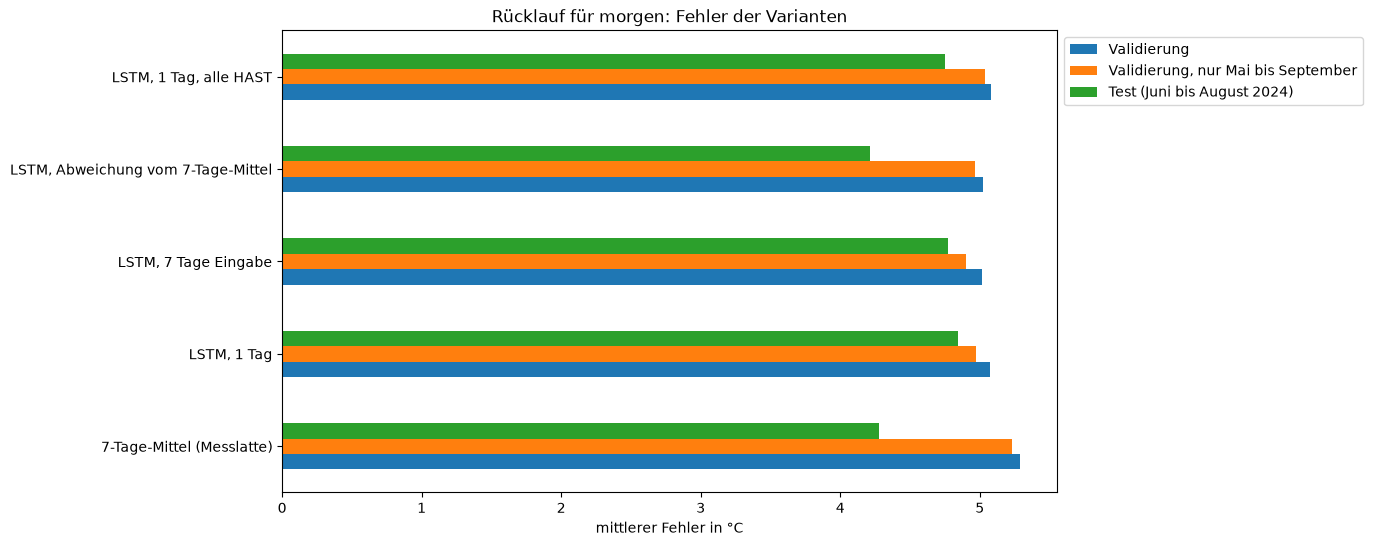

In [40]:
ax = vergleich.set_index("variante")[["validierung", "validierung_sommer", "test"]].plot.barh(figsize=(10, 6))
ax.set_title("Rücklauf für morgen: Fehler der Varianten")
ax.set_xlabel("mittlerer Fehler in °C")
ax.set_ylabel("")
ax.legend(["Validierung", "Validierung, nur Mai bis September", "Test (Juni bis August 2024)"],
          loc="upper left", bbox_to_anchor=(1, 1))

In [41]:
ax.figure.savefig(BILDER / "30_varianten.png", bbox_inches="tight")

- Alle LSTM-Varianten schlagen die Messlatte auf der Validierung, auch auf deren Sommertagen.
- Auf der Validierung liegen „7 Tage Eingabe“ und „Abweichung vom 7-Tage-Mittel“ gleichauf vorn (beide 5,02 K).
- Im Test gewinnt nur die Abweichung vom 7-Tage-Mittel, und das knapp (4,21 gegen 4,28 K). Diesen Testvorsprung als Grund für die Wahl zu nehmen, hieße nach dem Test auswählen.
- Alle HAST statt nur der begangenen bringen beim Vorhersagen kaum etwas (Validierung 5,08 gegen 5,07 K).
- **Warum sagt die Validierung so wenig über den Test?** An der Jahreszeit liegt es nicht, auch auf den Sommertagen der Validierung gewinnen alle LSTM. Die Validierungswochen liegen aber zwischen Trainingswochen: Das Netz kennt die Woche davor und danach und muss nur eine Lücke füllen. Der Test liegt nach dem ganzen Training, dort muss es wirklich in die Zukunft vorhersagen. Für die Endauswahl in Notebook 35 liegt die Probezeit deshalb zeitlich nach dem Lernen.

### 2.4 Außentemperatur von morgen

- Im Betrieb kennt man das Wetter von morgen nur aus der Vorhersage. Wie viel macht das aus? Einmal ganz ohne den fünften Kanal und einmal mit absichtlich verrauschter Temperatur, im Mittel 1,5 K daneben, ungefähr so gut wie eine Wettervorhersage für morgen.

In [42]:
modell_ohne_wetter = trainiere(eingabe[ist_train][:, :, :4], ziel[ist_train], eingabe[ist_val][:, :, :4], ziel[ist_val],
                               VORVERSUCHE / "vorhersage_ohne_wetter.pt")
p_ohne = vorhersage(modell_ohne_wetter, eingabe[:, :, :4]) * streuung[0] + mittel[0]

geladen: vorhersage_ohne_wetter.pt   beste Runde: 37   Validierungsfehler: 0.216


In [43]:
np.random.seed(1)
eingabe_rausch = eingabe.copy()
eingabe_rausch[:, :, 4] = eingabe_rausch[:, :, 4] + np.random.normal(0, 1.5 / streuung[3], size=(len(eingabe), 1))
p_rausch = vorhersage(modell, eingabe_rausch) * streuung[0] + mittel[0]

In [44]:
for name, p in [("mit Wetter von morgen", p_1), ("ohne Wetter von morgen", p_ohne), ("Wetter mit 1,5 Grad Fehler", p_rausch)]:
    print(name, "  Validierung:", np.abs(p[ist_val & ok] - wahr[ist_val & ok]).mean().round(2),
          "  Test:", np.abs(p[ist_test & ok] - wahr[ist_test & ok]).mean().round(2))

mit Wetter von morgen   Validierung: 5.07   Test: 4.84
ohne Wetter von morgen   Validierung: 5.13   Test: 4.8
Wetter mit 1,5 Grad Fehler   Validierung: 5.1   Test: 4.86


- Ohne das Wetter von morgen oder mit 1,5 K Fehler ändert sich der Fehler nur um wenige Hundertstel (Validierung 5,07, 5,13 und 5,10 K).
- Das Wetter von heute steckt schon in den Kanälen, und morgen ist es meist ähnlich. Eine Wettervorhersage reicht also als Eingang, ein genaues Wetter ist nicht nötig.

### 2.5 Was daraus für den Wächter folgt

| Frage | Ergebnis | Folge für den Wächter |
|---|---|---|
| Wie viele Tage Vorgeschichte? | U-Form, 7 Tage am besten | das Netz sieht die letzten 7 Tage |
| Hilft ein LSTM gegenüber dem 7-Tage-Mittel? | mit 7 Tagen Eingabe auf der Validierung am besten, im Test nur knapp | 7 Vortage als Eingabe, gelernt mit Early Stopping |
| Abweichung vom Mittel vorhersagen? | auf der Validierung gleichauf, im Test knapp vorn | nicht übernommen, der Vorsprung zeigt sich nur im Test |
| Alle HAST oder nur begangene? | beim Vorhersagen kaum ein Unterschied | Hauptmodell nach Vorgabe nur auf begangenen, Netz auf allen als Vergleich |
| Wetter von morgen? | kaum ein Einfluss | Außentemperatur des Zieltags als Eingang, die Wettervorhersage genügt |

Das endgültige Netz in Abschnitt 5 geht noch einen Schritt weiter als die Vorversuche. Es bekommt die 7 Vortage Stunde für Stunde und zusätzlich, was am Zieltag bekannt ist: die Außentemperatur aus dem Wetterbericht und den Vorlauf, den das Netz vorgibt. Vorhergesagt werden Rücklauf und Durchfluss, die beiden Größen, an denen sich Fehler zeigen.

## 3 Ein einfacher Wächter ohne Netz

- Wie weit kommt ein Wächter ganz ohne gelerntes Modell? Er sagt jeden Tag den Rücklauf mit dem 7-Tage-Mittel vorher und schaut, wie weit die Messung danebenliegt. Solange die Station sich wie immer verhält, liegt die Vorhersage so daneben wie sonst auch.
- Die Differenz ist Messung minus Vorhersage, gemittelt über die 24 Stunden. Positiv heißt: wärmer als erwartet.

In [45]:
X = X_alle
rl = pd.DataFrame(X[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = info["tag"]

mittel7 = np.full((len(info), 24), np.nan)
for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7[gruppe.index] = w.loc[gruppe["tag"]].values

In [46]:
info["differenz"] = (X[:, :, 0] - mittel7).mean(axis=1)
info["differenz"].describe()

count    21970.000000
mean         0.007510
std          3.769401
min        -46.036905
25%         -1.338095
50%         -0.002976
75%          1.335119
max         53.136905
Name: differenz, dtype: float64

- Bei 68956372 ging das Ventil am 08.08.2023 kaputt: Davor flossen nachts etwa 25 l/h, ab dem 19.08. dauerhaft rund 340 l/h. Das ist der einzige Schaden mit bekanntem Anfang.

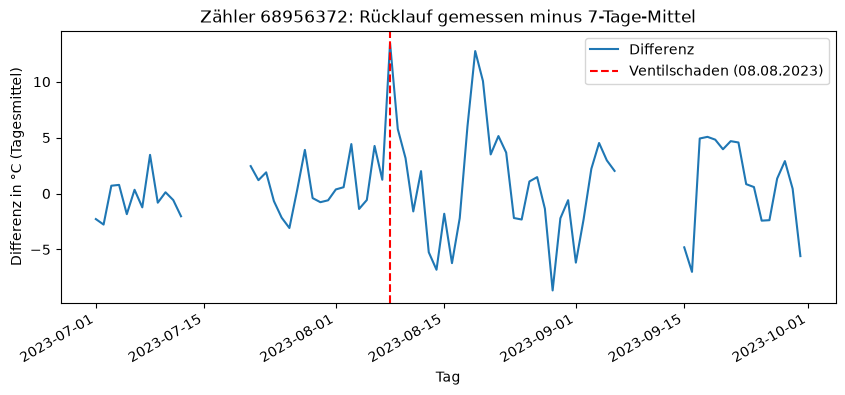

In [47]:
s = info[info["zaehler"] == 68956372].set_index("tag")
ax = s.loc["2023-07-01":"2023-09-30", "differenz"].plot(figsize=(10, 4))
ax.axvline(pd.Timestamp("2023-08-08"), color="red", linestyle="--")
ax.set_title("Zähler 68956372: Rücklauf gemessen minus 7-Tage-Mittel")
ax.set_xlabel("Tag")
ax.set_ylabel("Differenz in °C (Tagesmittel)")
ax.legend(["Differenz", "Ventilschaden (08.08.2023)"])

In [48]:
ax.figure.savefig(BILDER / "30_differenz_68956372.png", bbox_inches="tight")

- Am Schadenstag liegt die Messung 13 K über dem 7-Tage-Mittel, eine Woche später ist die Differenz wieder 0.
- Dann besteht das 7-Tage-Mittel nur noch aus Tagen mit kaputtem Ventil, und der Wächter hat sich an den Schaden gewöhnt. Er muss in den ersten Tagen anschlagen oder gar nicht.

### 3.1 Was ist unnormal?

- Bei einer ruhigen Station sind 2 K Differenz normal, bei einer taktenden 8 K. Deshalb ein Fenster je Station: Mittelwert und Streuung ihrer Differenzen in den letzten 8 Wochen.
- Die Differenz von heute, gemessen in diesen Streuungen, ist der **z-Wert**. `shift(1)`, damit der heutige Tag nicht in seinem eigenen Normalbereich steckt.

In [49]:
zwerte = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz"].asfreq("D")
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte[gruppe.index] = ((d - mittel) / streuung).loc[gruppe["tag"]].values
info["z"] = zwerte

In [50]:
info.loc[(info["zaehler"] == 68956372) & (info["tag"] == "2023-08-08"), "z"]

9533    5.872597
Name: z, dtype: float64

**Die Grenze.** Zu hoch heißt kein Alarm, auch beim echten Schaden. Zu niedrig heißt Alarm bei jeder Kleinigkeit. Fast alle Tage sind normal, die Alarme hier sind also fast alle Fehlalarme. Gezählt je Station und Jahr, in beide Richtungen:

In [51]:
jahre = info["z"].notna().sum() / 365
for grenze in [2, 3, 4, 5, 6]:
    alarme = (info["z"].abs() >= grenze).sum()
    print("Grenze", grenze, "  Alarmtage:", alarme, "  je Station und Jahr:", round(alarme / jahre, 1))

Grenze 2   Alarmtage: 1329   je Station und Jahr: 23.8
Grenze 3   Alarmtage: 327   je Station und Jahr: 5.8
Grenze 4   Alarmtage: 118   je Station und Jahr: 2.1
Grenze 5   Alarmtage: 63   je Station und Jahr: 1.1
Grenze 6   Alarmtage: 37   je Station und Jahr: 0.7


- **Warnregel, festgelegt nur über die Fehlalarme:** Alarm, wenn |z| ≥ 5. Das ist etwa 1 Alarm je Station und Jahr.
- Ob damit echte Schäden gefunden werden, prüft erst Abschnitt 3.3. Die Grenze wird nicht nach den Treffern gewählt.

Der Wächter bei 68956372 über die ganze Zeit:

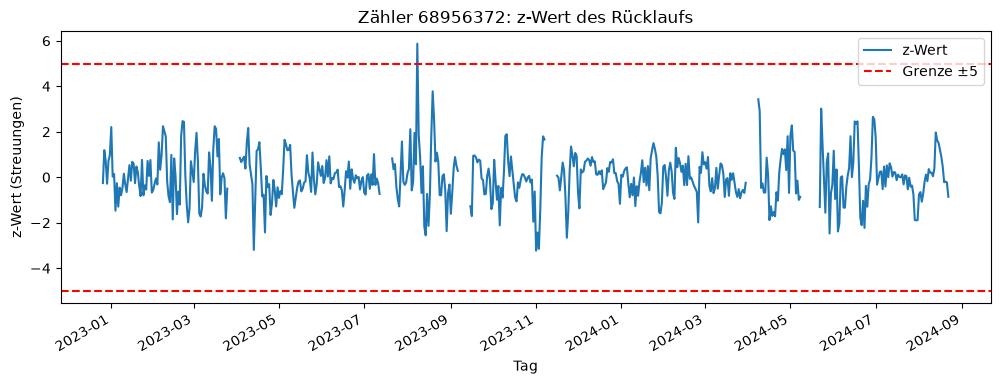

In [52]:
s = info[info["zaehler"] == 68956372].set_index("tag")
ax = s["z"].plot(figsize=(12, 4))
ax.axhline(5, color="red", linestyle="--")
ax.axhline(-5, color="red", linestyle="--")
ax.set_title("Zähler 68956372: z-Wert des Rücklaufs")
ax.set_xlabel("Tag")
ax.set_ylabel("z-Wert (Streuungen)")
ax.legend(["z-Wert", "Grenze ±5"])

In [53]:
ax.figure.savefig(BILDER / "30_z_68956372.png", bbox_inches="tight")

- Genau ein Alarm in fast zwei Jahren, am Schadenstag (z = 5,9).
- Insgesamt gibt es aber 63 Alarmtage. In welchen Monaten?

In [54]:
alarme_z = info[info["z"].abs() >= 5]
alarme_z["tag"].dt.month.value_counts().sort_index()

tag
1      1
2      2
3      4
4      3
5     11
6      6
7      2
8      6
10    10
11     9
12     9
Name: count, dtype: int64

### 3.2 Woher die Fehlalarme kommen

- Wie stark schwankt die Differenz in jedem Monat?

In [55]:
info.groupby(info["tag"].dt.month)["differenz"].std().round(2)

tag
1     4.05
2     3.65
3     3.62
4     4.38
5     4.35
6     3.75
7     2.48
8     2.56
9     2.59
10    4.50
11    4.19
12    4.01
Name: differenz, dtype: float64

- Die Alarme häufen sich im Mai und von Oktober bis Dezember, beim Heizende und beim Heizbeginn.
- Im Sommer liegt die Vorhersage etwa ±2,5 K daneben, im Oktober ±4,5 K. Am 1. Oktober enthält das Fenster aber vor allem August und September und hält ±2,5 K für normal. Ein gewöhnlicher Oktobertag, an dem die Heizung anspringt, liegt dann über 4 Streuungen weg.
- Idee: Heiztage nur mit Heiztagen und warme Tage nur mit warmen Tagen vergleichen:

In [56]:
heizzeit = info["tag"].dt.month.isin([10, 11, 12, 1, 2, 3, 4])
zwerte_saison = np.full(len(info), np.nan)
for (z, h), gruppe in info.groupby(["zaehler", heizzeit]):
    d = gruppe.set_index("tag")["differenz"]
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte_saison[gruppe.index] = ((d - mittel) / streuung).values
info["z_saison"] = zwerte_saison

In [57]:
for spalte in ["z", "z_saison"]:
    j = info[spalte].notna().sum() / 365
    a = info[info[spalte].abs() >= 5]
    print(spalte, "  Alarme je Station und Jahr:", round(len(a) / j, 2))
    print(a["tag"].dt.month.value_counts().sort_index().to_dict())

z   Alarme je Station und Jahr: 1.13
{1: 1, 2: 2, 3: 4, 4: 3, 5: 11, 6: 6, 7: 2, 8: 6, 10: 10, 11: 9, 12: 9}
z_saison   Alarme je Station und Jahr: 1.08
{1: 1, 2: 2, 3: 4, 4: 3, 5: 13, 6: 5, 7: 2, 8: 6, 10: 3, 11: 8, 12: 9}


- Kaum ein Unterschied: 1,08 statt 1,13 Alarme je Station und Jahr, im Oktober 3 statt 10, im Mai aber 13 statt 11.
- Der Rückgang im Oktober täuscht: Stationen mit Daten erst ab September 2023 haben vorher keine Heiztage und bekommen anfangs gar keinen z-Wert. Der Wächter schaut dort weniger hin, statt besser.
- Die Idee bleibt trotzdem richtig: Die Streuung hängt an der Jahreszeit. Der endgültige Wächter misst sie deshalb getrennt für Heiztage und warme Tage (Faktor je Jahreszeit, Abschnitt 8).

### 3.3 Wie groß muss ein Schaden sein?

- Weitere Schäden mit bekanntem Anfang gibt es nicht. Die Begehung ist das Ende eines Schadens, nicht sein Anfang.
- Deshalb werden Schäden rechnerisch eingebaut, wie Prüfspray beim Rauchmelder: Ab einem Tag steigt der Messwert um einen festen Betrag. Am ersten Tag ist das Fenster noch unverändert, nur die Differenz von heute wird größer. Der z-Wert steigt also um Sprung / Streuung, und jeder Tag kann einmal Schadenstag sein.

In [58]:
fenster_streuung = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz"].asfreq("D")
    fenster_streuung[gruppe.index] = d.rolling(56, min_periods=28).std().shift(1).loc[gruppe["tag"]].values
info["streuung"] = fenster_streuung

In [59]:
ok = info["z"].notna()
for sprung in [0, 2, 5, 10, 15, 20]:
    z_neu = info.loc[ok, "z"] + sprung / info.loc[ok, "streuung"]
    print(sprung, "Grad:  erkannt an", round((z_neu.abs() >= 5).mean() * 100), "% der Tage")

0 Grad:  erkannt an 0 % der Tage
2 Grad:  erkannt an 4 % der Tage
5 Grad:  erkannt an 11 % der Tage
10 Grad:  erkannt an 37 % der Tage
15 Grad:  erkannt an 60 % der Tage
20 Grad:  erkannt an 76 % der Tage


- Ein Sprung von 10 K im Rücklauf wird am ersten Tag nur an 37 % der Tage erkannt, die Hälfte erst bei 12 bis 15 K.
- Bei einer unruhigen Station sind 10 K nur 2 Streuungen.
- Beim Ventil ist der Durchfluss das deutlichere Signal: Bei 68956372 stieg der Rücklauf um ein Viertel, der Durchfluss nachts auf das 14-Fache. Derselbe Wächter für den Durchfluss:

In [60]:
fl = pd.DataFrame(X[:, :, 1])
fl["zaehler"] = info["zaehler"]
fl["tag"] = info["tag"]

mittel7_fl = np.full((len(info), 24), np.nan)
for z, gruppe in fl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7_fl[gruppe.index] = w.loc[gruppe["tag"]].values

info["differenz_fl"] = (X[:, :, 1] - mittel7_fl).mean(axis=1)

In [61]:
zwerte_fl = np.full(len(info), np.nan)
streuung_fl = np.full(len(info), np.nan)
for z, gruppe in info.groupby("zaehler"):
    d = gruppe.set_index("tag")["differenz_fl"].asfreq("D")
    mittel = d.rolling(56, min_periods=28).mean().shift(1)
    streuung = d.rolling(56, min_periods=28).std().shift(1)
    zwerte_fl[gruppe.index] = ((d - mittel) / streuung).loc[gruppe["tag"]].values
    streuung_fl[gruppe.index] = streuung.loc[gruppe["tag"]].values
info["z_fl"] = zwerte_fl
info["streuung_fl"] = streuung_fl

In [62]:
jahre_fl = info["z_fl"].notna().sum() / 365
print("Alarme je Station und Jahr:", round((info["z_fl"].abs() >= 5).sum() / jahre_fl, 2))
info.loc[(info["zaehler"] == 68956372) & (info["tag"] == "2023-08-08"), "z_fl"]

Alarme je Station und Jahr: 1.27


9533    12.822429
Name: z_fl, dtype: float64

- Auch beim Durchfluss passt die Grenze 5 ins Budget: 1,27 Fehlalarme je Station und Jahr.
- Am Schadenstag von 68956372 ist z = 12,8 statt 5,9 beim Rücklauf. Jetzt das Prüfspray im Durchfluss:

In [63]:
ok_fl = info["z_fl"].notna()
for sprung in [0, 25, 50, 100, 150, 200]:
    z_neu = info.loc[ok_fl, "z_fl"] + sprung / info.loc[ok_fl, "streuung_fl"]
    print(sprung, "l/h:  erkannt an", round((z_neu.abs() >= 5).mean() * 100), "% der Tage")

0 l/h:  erkannt an 0 % der Tage
25 l/h:  erkannt an 4 % der Tage
50 l/h:  erkannt an 18 % der Tage
100 l/h:  erkannt an 48 % der Tage
150 l/h:  erkannt an 65 % der Tage
200 l/h:  erkannt an 75 % der Tage


Für die Abbildung mit Grenze 4 und 5:

In [64]:
kurve = []
for sprung in [0, 25, 50, 75, 100, 150, 200, 300]:
    z_neu = info.loc[ok_fl, "z_fl"] + sprung / info.loc[ok_fl, "streuung_fl"]
    kurve.append({"sprung": sprung, "grenze 4": (z_neu.abs() >= 4).mean() * 100, "grenze 5": (z_neu.abs() >= 5).mean() * 100})
kurve = pd.DataFrame(kurve).set_index("sprung")
kurve.round(0)

,grenze 4,grenze 5
sprung,,
0,1.0,0.0
25,8.0,4.0
50,27.0,18.0
75,46.0,35.0
100,58.0,48.0
150,73.0,65.0
200,82.0,75.0
300,91.0,87.0


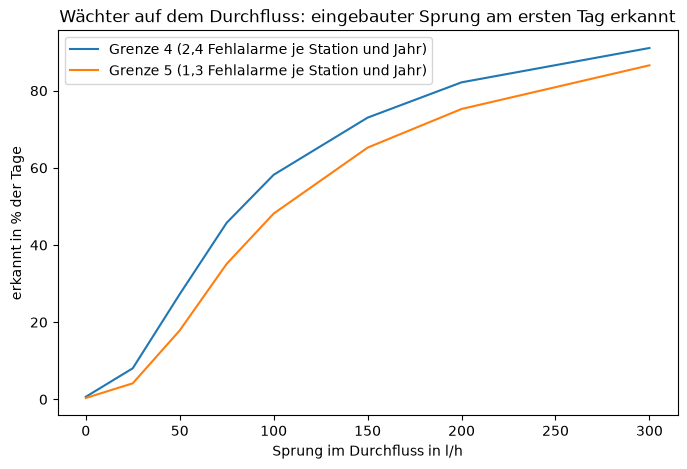

In [65]:
ax = kurve.plot(figsize=(8, 5))
ax.set_title("Wächter auf dem Durchfluss: eingebauter Sprung am ersten Tag erkannt")
ax.set_xlabel("Sprung im Durchfluss in l/h")
ax.set_ylabel("erkannt in % der Tage")
ax.legend(["Grenze 4 (2,4 Fehlalarme je Station und Jahr)", "Grenze 5 (1,3 Fehlalarme je Station und Jahr)"])

In [66]:
ax.figure.savefig(BILDER / "30_pruefspray_durchfluss.png", bbox_inches="tight")

- Bei der Grenze 5 werden 150 l/h zusätzlich an 65 % der Tage erkannt, 50 l/h nur an 18 %.
- Die Grenze 4 findet bei 150 l/h 73 statt 65 %, kostet aber fast doppelt so viele Fehlalarme. Die Grenze bleibt bei 5, sie war vorher über die Fehlalarme festgelegt.
- Beim Ventil ist der Durchfluss der bessere Kanal. Der endgültige Wächter überwacht deshalb Rücklauf und Nachtdurchfluss.

### 3.4 Der einfache Wächter an den echten Begehungen

- Dafür braucht es die Tage nach dem Stichtag, für alle Zähler, auch die nie begangenen. Das Tagesmittel reicht.
- Verglichen wird mit den nie begangenen Zählern im selben Zeitfenster, wie mit einer Placebo-Gruppe. Die meisten Begehungen waren zum Heizbeginn, wo es ohnehin viele Alarme gibt.

In [67]:
zeilen = []
for datei in sorted(METER_DIR.glob("*.csv")):
    d = pd.read_csv(datei, parse_dates=["Timestamp"])
    d = d[d["Timestamp"] >= "2022-11-01"]
    d["tag"] = d["Timestamp"].dt.normalize()
    d["stunde"] = d["Timestamp"].dt.hour
    rl_tag = d.pivot(index="tag", columns="stunde", values="Return temperature (°C)")
    fl_tag = d.pivot(index="tag", columns="stunde", values="Volume flow (l/h)")
    voll = rl_tag.notna().all(axis=1) & fl_tag.notna().all(axis=1)
    zeilen.append(pd.DataFrame({"zaehler": int(datei.stem), "rl": rl_tag.mean(axis=1), "fl": fl_tag.mean(axis=1)})[voll])
tage_einfach = pd.concat(zeilen).reset_index()
tage_einfach.shape

(68586, 4)

In [68]:
for kanal in ["rl", "fl"]:
    zwerte = np.full(len(tage_einfach), np.nan)
    for z, gruppe in tage_einfach.groupby("zaehler"):
        s = gruppe.set_index("tag")[kanal].asfreq("D")
        differenz = s - s.rolling(7).mean().shift(1)
        mittel = differenz.rolling(56, min_periods=28).mean().shift(1)
        streuung = differenz.rolling(56, min_periods=28).std().shift(1)
        zwerte[gruppe.index] = ((differenz - mittel) / streuung).loc[gruppe["tag"]].values
    tage_einfach["z_" + kanal] = zwerte
tage_einfach["alarm"] = (tage_einfach["z_rl"].abs() >= 5) | (tage_einfach["z_fl"].abs() >= 5)      

In [69]:
tage_einfach.loc[(tage_einfach["zaehler"] == 68956372) & (tage_einfach["tag"] == "2023-08-08"), ["z_rl", "z_fl"]]

,z_rl,z_fl
22232,5.872597,12.822429


In [70]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
nie_begangen = ~tage_einfach["zaehler"].isin(labels["zaehler"])
tage_einfach["hat_z"] = tage_einfach["z_rl"].notna() | tage_einfach["z_fl"].notna()

treffer = []
kontrolle = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage_einfach["tag"] >= b["erste_begehung"]) & (tage_einfach["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage_einfach["hat_z"]
    station = tage_einfach[im_fenster & (tage_einfach["zaehler"] == b["zaehler"])]
    andere = tage_einfach[im_fenster & nie_begangen].groupby("zaehler").agg(tage_einfach=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage_einfach"] >= 5]
    if len(station) >= 5 and len(andere) >= 5:
        treffer.append(station["alarm"].any())
        kontrolle.append(andere["alarm"].mean())
print("Begehungen mit Alarm:", sum(treffer), "von", len(treffer))
print("Kontrollstationen mit Alarm im selben Zeitraum:", round(np.mean(kontrolle) * 100), "%")

Begehungen mit Alarm: 16 von 41
Kontrollstationen mit Alarm im selben Zeitraum: 20 %


Binomialtest: Wie wahrscheinlich sind so viele Treffer, wenn jede Begehung nur die Chance einer Kontrollstation hätte?

In [71]:
binomtest(sum(treffer), len(treffer), np.mean(kontrolle), alternative="greater").pvalue

np.float64(0.004397036110561569)

Der Ventiltausch an 68956351 am 09.09.2024:

In [72]:
tage_einfach.loc[(tage_einfach["zaehler"] == 68956351) & (tage_einfach["tag"] >= "2024-09-07") & (tage_einfach["tag"] <= "2024-09-12"), ["tag", "z_rl", "z_fl", "alarm"]]

,tag,z_rl,z_fl,alarm
10543,2024-09-07,0.152866,0.796860,False
10544,2024-09-08,-0.166196,1.779126,False
10545,2024-09-09,-2.876167,-15.264191,True
10546,2024-09-10,-9.413573,-19.165505,True
10547,2024-09-11,-4.453095,-5.477328,True
10548,2024-09-12,-3.269780,-3.164978,False


**Ein Verdacht.** Am Begehungstag arbeitet der Techniker an der Station. Kommen die Alarme nur davon? An welchem Tag nach der Begehung kommt der erste Alarm, und was bleibt, wenn das Fenster erst 2 Tage danach beginnt?

In [73]:
tage_einfach_bis_alarm = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage_einfach["tag"] >= b["erste_begehung"]) & (tage_einfach["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage_einfach["hat_z"]
    station = tage_einfach[im_fenster & (tage_einfach["zaehler"] == b["zaehler"])]
    andere = tage_einfach[im_fenster & nie_begangen].groupby("zaehler").agg(tage_einfach=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage_einfach"] >= 5]
    if len(station) >= 5 and len(andere) >= 5 and station["alarm"].any():
        tage_einfach_bis_alarm.append((station.loc[station["alarm"], "tag"].min() - b["erste_begehung"]).days)
pd.Series(tage_einfach_bis_alarm).value_counts().sort_index()

0    8
1    4
2    3
7    1
Name: count, dtype: int64

In [74]:
treffer = []
kontrolle = []
for _, b in labels.dropna(subset=["erste_begehung"]).iterrows():
    im_fenster = (tage_einfach["tag"] >= b["erste_begehung"] + pd.Timedelta(days=2)) & (tage_einfach["tag"] <= b["erste_begehung"] + pd.Timedelta(days=14)) & tage_einfach["hat_z"]
    station = tage_einfach[im_fenster & (tage_einfach["zaehler"] == b["zaehler"])]
    andere = tage_einfach[im_fenster & nie_begangen].groupby("zaehler").agg(tage_einfach=("tag", "size"), alarm=("alarm", "any"))
    andere = andere[andere["tage_einfach"] >= 5]
    if len(station) >= 5 and len(andere) >= 5:
        treffer.append(station["alarm"].any())
        kontrolle.append(andere["alarm"].mean())
print("Begehungen mit Alarm:", sum(treffer), "von", len(treffer), "  Kontrolle:", round(np.mean(kontrolle) * 100), "%")
binomtest(sum(treffer), len(treffer), np.mean(kontrolle), alternative="greater").pvalue

Begehungen mit Alarm: 9 von 41   Kontrolle: 18 %


np.float64(0.29955898510731377)

- Ohne Verdacht sieht es gut aus: Nach 16 von 41 Begehungen gibt es in 14 Tagen einen Alarm, bei den Kontrollstationen im selben Zeitraum nur bei 20 % (p = 0,004). Beim Ventiltausch an 68956351 kommt der Alarm am Tag des Tauschs (Durchfluss z = −15).
- 12 der 16 Treffer liegen aber am Begehungstag oder am Tag danach. Ab Tag 2 sind es 9 von 41 gegen 18 %, p = 0,30, also kein Unterschied mehr.
- Der einfache Wächter bemerkt also den Eingriff selbst, nicht die kleine bleibende Veränderung danach. Laut Notebook 30 verschiebt eine Begehung den Betrieb im Median nur um etwa eine halbe Streuung. Ein CUSUM zählt so eine Verschiebung Tag für Tag auf, eine Grenze von 5 Streuungen sieht sie nie.

### 3.5 Was aus den Vorversuchen folgt

| Ergebnis des einfachen Wächters | Folge für den endgültigen Wächter |
|---|---|
| Das 7-Tage-Mittel ist eine schwache Erwartung, und der Wächter gewöhnt sich nach einer Woche an einen Schaden | gelernte Erwartung aus Vorwoche, Wetter und Vorlauf (Abschnitt 5 bis 7) |
| Was normal ist, hängt an der Station und der Jahreszeit | z-Wert je Station aus ihrer eigenen Schwankung, Faktor je Jahreszeit (Abschnitt 8) |
| Beim Ventil zeigt der Durchfluss den Fehler deutlicher | zwei Kanäle: Rücklauf über den Tag und Durchfluss in der Nacht |
| Am Begehungstag schlägt jeder Wächter an | Warnung erst bei zwei auffälligen Tagen hintereinander |
| Kleine bleibende Verschiebungen sieht eine feste Grenze nie | in Notebook 35 CUSUM, das kleine Abweichungen aufsummiert |
| Grenze nur über die Fehlalarme festgelegt | Schwelle über die Fehlalarmrate in der Testzeit, später gleiche Alarmlast für alle Wächter (Notebook 35) |

## 4 Der Wächter: Daten laden und ansehen

- Lädt Stundenwerte und Labels aus Notebook 25.

In [75]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
print(f"stunden: {stunden.shape[0]:,} Zeilen, {stunden['zaehler'].nunique()} Zähler; labels: {len(labels)} begangene Zähler")
stunden[["ruecklauf", "durchfluss", "vorlauf", "aussen"]].describe().round(1)

stunden: 2,128,400 Zeilen, 93 Zähler; labels: 56 begangene Zähler


,ruecklauf,durchfluss,vorlauf,aussen
count,1692166.0,1692110.0,1692166.0,2127727.0
mean,46.2,327.7,63.0,11.1
std,15.3,1405.3,15.5,8.4
min,8.6,-999.0,9.5,-13.8
25%,33.0,0.0,56.3,4.9
50%,45.7,53.0,69.4,10.4
75%,57.1,186.0,73.9,16.9
max,89.0,26135.0,91.5,40.4


- 93 Zähler in den Stundenwerten, 56 begangene Zähler mit Label.
- Die Tabelle zeigt die vier Größen des Wächters: Rücklauf, Durchfluss, Vorlauf und Außentemperatur. Die Wertebereiche entsprechen Notebook 25.

In [76]:
KANAELE = ["ruecklauf", "durchfluss", "vorlauf", "aussen"]
RL, FL, VL, AT = range(4)
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden = stunden[stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24].sort_values(["zaehler", "timestamp"])
werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

#Hat ein Tag sieben vollständige Vortage desselben Zählers direkt davor?
mit_vorgeschichte = pd.Series(True, index=tage.index)
for k in range(1, VORGESCHICHTE + 1):
    mit_vorgeschichte &= (tage["zaehler"].shift(k) == tage["zaehler"]) & (tage["tag"].shift(k) == tage["tag"] - pd.Timedelta(days=k))

grenze = tage["zaehler"].map(labels["erste_begehung"].clip(upper=STICHTAG)).fillna(STICHTAG)
woche = tage["tag"].dt.to_period("W").astype(str)
lernwochen = woche[tage["tag"] < LERNEN_BIS].unique()
val_wochen = np.random.default_rng(SEED).choice(lernwochen, size=int(0.1 * len(lernwochen)), replace=False)
tage["abschnitt"] = np.select(
    [tage["tag"] >= grenze, tage["tag"] >= LERNEN_BIS, woche.isin(val_wochen)],
    ["nach der Begehung", "Test (Sommer 2024)", "Validierung"], "Training")
tage["begangen"] = tage["zaehler"].isin(labels.index)
tage["heiztag"] = werte[:, :, AT].mean(axis=1) < HEIZGRENZE_C

ziel_idx = np.flatnonzero(mit_vorgeschichte)
pd.crosstab(tage.loc[ziel_idx, "abschnitt"], tage.loc[ziel_idx, "begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            margins=True, margins_name="Summe")

begangen,begangene HAST,nie begangen,Summe
abschnitt,,,
Test (Sommer 2024),3974,2429,6403
Training,16518,10856,27374
Validierung,1478,1066,2544
nach der Begehung,15430,8560,23990
Summe,37400,22911,60311


- Baut wie in Notebook 27 das Feld der vollständigen Tage, diesmal mit vier Größen.
- Ein Tag kann nur vorhergesagt werden, wenn die sieben Tage davor lückenlos vorliegen.
- Jeder Zieltag bekommt einen Abschnitt. Dazu wird vermerkt, ob der Zähler begangen wurde und ob es ein Heiztag ist.

| Abschnitt | Zeitraum | wofür |
|---|---|---|
| Training | bis Mai 2024 | Gewichte lernen (Hauptmodell: nur begangene HAST) |
| Validierung | 10 % der Wochen bis Mai 2024 | Early Stopping (Training stoppen, wenn die Validierung nicht mehr besser wird), normale Schwankung je Station |
| Test (Sommer 2024) | Juni bis August 2024, vor jeder Begehung | Fehlalarme zählen, Fehler einrechnen |
| nach der Begehung | ab der Begehung bzw. ab dem Stichtag | eigentlicher Überwachungsbetrieb |

### 4.1 Skalierung und Eingänge

- Skaliert wird wie in Notebook 27: Durchfluss je Zähler durch sein 95-%-Quantil, Temperaturen für alle gleich. Die Skalen kommen aus der Lernzeit aller Zähler; das ist nur Umrechnen, kein Lernen aus Labels.
- Je Zieltag entstehen drei Teile:
  - Vergangenheit: die 7 Vortage, Stunde für Stunde (168 × 4)
  - Zieltag bekannt: Außentemperatur und Vorlauf des Zieltags (24 × 2). Das Wetter steht im Wetterbericht, den Vorlauf gibt das Netz vor.
  - Ziel: Rücklauf und Durchfluss des Zieltags (24 × 2)

In [77]:
lernzeit = (tage["abschnitt"] == "Training").to_numpy()
fl_teiler = stunden[np.repeat(lernzeit, 24)].groupby("zaehler")["durchfluss"].quantile(0.95).clip(lower=1.0)
mittel = {k: werte[lernzeit, :, i].mean() for i, k in enumerate(KANAELE) if k != "durchfluss"}
streuung = {k: werte[lernzeit, :, i].std() for i, k in enumerate(KANAELE) if k != "durchfluss"}


def skalieren(feld):
    x = feld.copy()
    for i, k in enumerate(KANAELE):
        if k == "durchfluss":
            x[:, :, i] /= tage["zaehler"].map(fl_teiler).fillna(1.0).to_numpy(dtype=np.float32)[:, None]
        else:
            x[:, :, i] = (x[:, :, i] - mittel[k]) / streuung[k]
    return x


def eingaenge(x, idx):
    vergangenheit = x[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].reshape(len(idx), VORGESCHICHTE * 24, len(KANAELE))
    return torch.tensor(vergangenheit), torch.tensor(x[idx][:, :, [AT, VL]]), torch.tensor(x[idx][:, :, [RL, FL]])


x = skalieren(werte)
#Überwacht werden nur Zähler, die vor Juni 2024 Daten haben (sonst keine Skala und keine normale Schwankung)
ohne_lernzeit = sorted(set(tage["zaehler"]) - set(fl_teiler.index))
ziel_idx = ziel_idx[tage.loc[ziel_idx, "zaehler"].isin(fl_teiler.index).to_numpy()]
print(f"{len(ohne_lernzeit)} Zähler ohne Tage vor Juni 2024 werden nicht überwacht; {len(ziel_idx):,} Zieltage bleiben")
v, z, y = eingaenge(x, ziel_idx[:3])
print(f"Beispiel für drei Zieltage: Vergangenheit {tuple(v.shape)}, Zieltag bekannt {tuple(z.shape)}, Ziel {tuple(y.shape)}")

3 Zähler ohne Tage vor Juni 2024 werden nicht überwacht; 59,683 Zieltage bleiben
Beispiel für drei Zieltage: Vergangenheit (3, 168, 4), Zieltag bekannt (3, 24, 2), Ziel (3, 24, 2)


- `skalieren()` ist eine Funktion, weil sie später noch einmal gebraucht wird: auf Daten mit eingerechneten Fehlern.
- `eingaenge()` holt für eine Liste von Zieltagen die drei Teile. `idx[:, None] + np.arange(-7, 0)` sind je Zieltag die Positionen der sieben Vortage im Feld.
- 3 Zähler ohne Tage vor Juni 2024 werden nicht überwacht. Es bleiben 59.683 Zieltage.

## 5 Das Netz: Encoder-Decoder

```
7 Vortage (168 × 4) ──► LSTM-Encoder (64) ──► Zustand
                                                │
     Zieltag: Außentemperatur, Vorlauf (24 × 2) ──► LSTM-Decoder (64) ──► Rücklauf, Durchfluss (24 × 2)
```

- Der Encoder liest die Woche und gibt seinen Zustand an den Decoder weiter.
- Der Decoder läuft durch die 24 Stunden des Zieltags und bekommt zu jeder Stunde, was bekannt ist.

In [78]:
class Prognose(nn.Module):
    def __init__(self, versteckt=64):
        super().__init__()
        self.encoder = nn.LSTM(len(KANAELE), versteckt, batch_first=True)
        self.decoder = nn.LSTM(2, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, 2)

    def forward(self, vergangenheit, zieltag):
        _, zustand = self.encoder(vergangenheit)
        y, _ = self.decoder(zieltag, zustand)
        return self.ausgang(y)


print(Prognose())
print(f"{sum(p.numel() for p in Prognose().parameters()):,} lernbare Gewichte")

Prognose(
  (encoder): LSTM(4, 64, batch_first=True)
  (decoder): LSTM(2, 64, batch_first=True)
  (ausgang): Linear(in_features=64, out_features=2, bias=True)
)
35,458 lernbare Gewichte


- Zwei `nn.LSTM` und eine `nn.Linear`, zusammen 35.458 lernbare Gewichte.
- Die Zeile `self.decoder(zieltag, zustand)` startet den Decoder mit dem Gedächtnis des Encoders.

## 6 Training: Hauptmodell (begangene HAST) und Vergleich (alle HAST)

- Zwei Netze mit derselben Trainingsschleife: eines nur auf Tagen begangener HAST (Vorgabe), eines auf allen HAST.
- Beide lernen nur aus der Lernzeit bis Mai 2024.

begangen  Gewichte geladen aus notebooks/models/prognose_lstm_begangen.pt
          16,518 Trainings- und 1,478 Validierungstage; bester Validierungsfehler 0.1000 nach 141 Runden
alle      Gewichte geladen aus notebooks/models/prognose_lstm_alle.pt
          27,374 Trainings- und 2,544 Validierungstage; bester Validierungsfehler 0.1035 nach 132 Runden


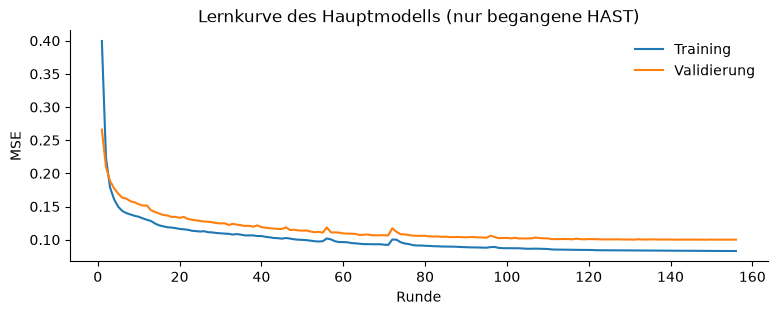

In [79]:
abschnitt = tage.loc[ziel_idx, "abschnitt"].to_numpy()
begangen = tage.loc[ziel_idx, "begangen"].to_numpy()
LERNMENGEN = {
    "begangen": (ziel_idx[(abschnitt == "Training") & begangen], ziel_idx[(abschnitt == "Validierung") & begangen]),
    "alle": (ziel_idx[abschnitt == "Training"], ziel_idx[abschnitt == "Validierung"]),
}


def trainieren(lern_idx, val_idx, max_runden=200, geduld=15, stapel=512):
    torch.manual_seed(SEED)
    modell = Prognose().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=2e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4, min_lr=1e-5)
    vv, vz, vy = (t.to(GERAET) for t in eingaenge(x, val_idx))
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern_idx), max(1, len(lern_idx) // stapel)):
            tv, tz, ty = (t.to(GERAET) for t in eingaenge(x, teil))
            verlust = nn.functional.mse_loss(modell(tv, tz), ty)
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            val = nn.functional.mse_loss(modell(vv, vz), vy).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern_idx), "validierung": val})
        plan.step(val)
        if val < bester - 1e-5:
            bester, ohne_besserung = val, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"prognose_lstm_{name}.pt"
    lern_idx, val_idx = LERNMENGEN[name]
    if SELBST_TRAINIEREN:
        start = time.time()
        modell, verlauf = trainieren(lern_idx, val_idx)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:9s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    else:
        modell = Prognose().to(GERAET)
        gespeichert = gewichte_laden(datei)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:9s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    print(f"          {len(lern_idx):,} Trainings- und {len(val_idx):,} Validierungstage; bester Validierungsfehler "
          f"{verlauf['validierung'].min():.4f} nach {verlauf['validierung'].idxmin() + 1} Runden")
    modell.eval()
    return modell, verlauf


modelle = {}
for name in ("begangen", "alle"):
    modelle[name], verlauf = laden_oder_trainieren(name)
    if name == "begangen":
        verlauf_haupt = verlauf

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(verlauf_haupt["runde"], verlauf_haupt["training"], label="Training")
ax.plot(verlauf_haupt["runde"], verlauf_haupt["validierung"], label="Validierung")
ax.set_xlabel("Runde")
ax.set_ylabel("MSE")
ax.set_title("Lernkurve des Hauptmodells (nur begangene HAST)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

- Dieselbe Trainingsschleife wie in Notebook 27. Neu: Die Stapel werden mit `eingaenge()` erst beim Lernen zusammengestellt. Alle Vorgeschichten auf einmal kosten viel Speicher, weil jeder Tag in sieben Vorgeschichten vorkommt.
- Hauptmodell: 16.518 Trainings- und 1.478 Validierungstage, 24 Sekunden, bester Validierungsfehler 0,1000 nach 141 Runden.
- Vergleich: 27.374 Trainings- und 2.544 Validierungstage, 36 Sekunden, bester Validierungsfehler 0,1035 nach 132 Runden.

## 7 Wie gut ist die Vorhersage?

- Ein guter Wächter muss besser vorhersagen als einfache Regeln. Zwei Vergleiche: „wie gestern“ (morgen verläuft wie heute) und „Mittel der Woche“ (jede Stunde = Mittel dieser Stunde über die letzten 7 Tage).
- Gemessen wird der mittlere absolute Fehler (MAE) in echten Einheiten, auf Tagen, die keines der beiden Netze zum Lernen gesehen hat.
- Getrennt ausgewiesen: nie begangene Zähler, die das Hauptmodell nie gesehen hat.

In [80]:
def vorhersagen(modell, feld_skaliert, idx, stapel=4096):
    teile = []
    with torch.no_grad():
        for start in range(0, len(idx), stapel):
            v, z, _ = eingaenge(feld_skaliert, idx[start:start + stapel])
            teile.append(modell(v.to(GERAET), z.to(GERAET)).cpu().numpy())
    p = np.concatenate(teile)
    rl = p[:, :, 0] * streuung["ruecklauf"] + mittel["ruecklauf"]                         #zurück in °C
    fl = p[:, :, 1] * tage.loc[idx, "zaehler"].map(fl_teiler).to_numpy()[:, None]         #zurück in l/h
    return rl, fl


zeilen = []
for abschnitt_name in ("Validierung", "Test (Sommer 2024)"):
    for gruppe, maske in (("begangene HAST", begangen), ("nie begangen", ~begangen)):
        idx = ziel_idx[(abschnitt == abschnitt_name) & maske]
        echt = werte[idx]
        kandidaten = {"wie gestern": (werte[idx - 1][:, :, RL], werte[idx - 1][:, :, FL])}
        woche_mittel = werte[idx[:, None] + np.arange(-VORGESCHICHTE, 0)].mean(axis=1)
        kandidaten["Mittel der Woche"] = (woche_mittel[:, :, RL], woche_mittel[:, :, FL])
        for name, m in modelle.items():
            kandidaten[f"LSTM ({name})"] = vorhersagen(m, x, idx)
        for verfahren, (rl_v, fl_v) in kandidaten.items():
            zeilen.append({"Abschnitt": abschnitt_name, "Zähler": gruppe, "Verfahren": verfahren, "Tage": len(idx),
                           "MAE Rücklauf [K]": np.abs(rl_v - echt[:, :, RL]).mean(),
                           "MAE Durchfluss [l/h]": np.abs(fl_v - echt[:, :, FL]).mean()})
guete = pd.DataFrame(zeilen).set_index(["Abschnitt", "Zähler", "Verfahren"])
guete.round(2)

Tage  MAE Rücklauf [K]  MAE Durchfluss [l/h]
Abschnitt          Zähler         Verfahren                                                     
Validierung        begangene HAST wie gestern       1478              6.18                 60.15
                                  Mittel der Woche  1478              5.73                 58.60
                                  LSTM (begangen)   1478              4.27                 43.94
                                  LSTM (alle)       1478              4.15                 43.81
                   nie begangen   wie gestern       1066              6.12                142.33
                                  Mittel der Woche  1066              5.42                139.72
                                  LSTM (begangen)   1066              5.33                207.92
                                  LSTM (alle)       1066              4.07                126.23
Test (Sommer 2024) begangene HAST wie gestern       3974              4.70                 26.98
                                  Mittel der Woche  3974              4.28                 25.79
                                  LSTM (begangen)   3974              2.20                 28.17
                                  LSTM (alle)       3974              2.14                 26.94
                   nie begangen   wie gestern       2409              4.34                147.60
                                  Mittel der Woche  2409              4.06                184.23
                                  LSTM (begangen)   2409              2.68                235.63
                                  LSTM (alle)       2409              2.09                164.47

- `vorhersagen()` schickt Zieltage in Stapeln durchs Netz und rechnet zurück in °C und l/h.
- Die Vergleichsverfahren brauchen kein Netz: „wie gestern“ ist der Vortag, „Mittel der Woche“ das stündliche Mittel der sieben Vortage.
- Bei den nie begangenen Zählern zeigt sich, ob das Hauptmodell verallgemeinert.

- Begangene HAST: Beide Netze sind gleich gut und beim Rücklauf klar besser als die Regeln. Validierung 4,3 bzw. 4,2 K gegen 6,2 K („wie gestern“), Sommer 2,2 bzw. 2,1 K gegen 4,7 K.
- Durchfluss im Sommer: alle Verfahren bei 26 bis 28 l/h. Der Sommerdurchfluss besteht fast nur aus Warmwasserspitzen, und wann jemand duscht, kann kein Modell vorhersagen.
- Nie begangene Zähler zeigen den Preis der Vorgabe:
  - Rücklauf: Hauptmodell 5,3 K (Validierung) bzw. 2,7 K (Sommer), besser als „wie gestern“ (6,1 bzw. 4,3 K), aber schlechter als das Netz auf allen HAST (4,1 bzw. 2,1 K).
  - Durchfluss: 208 bzw. 236 l/h, schlechter als „wie gestern“ (142 bzw. 148 l/h). Unter den nie begangenen sind große Abnehmer, deren Durchfluss das Netz nie kennengelernt hat.
- Für die Fehlererkennung (Notebook 27) ist die Vorgabe ohne Nachteil. Ein Wächter über alle Stationen sollte aber alle kennen. Die Warnungen bleiben trotzdem fair, weil jede Station an ihrer eigenen Schwankung gemessen wird; schlecht vorhergesagte Stationen werden nur unempfindlicher überwacht.

## 8 Von der Abweichung zur Warnung

- Je Tag zwei Abweichungen, jeweils gemessen minus vorhergesagt:
  - Rücklauf: mittlere Abweichung über den Tag [K]. Ein falscher Sollwert, ein hängender Fühler oder ein Bypass heben oder senken ihn.
  - Nachtdurchfluss: mittlere Abweichung zwischen 0 und 5 Uhr [l/h]. Nachts sollte kaum Wasser fließen; ein offenes Ventil zeigt sich hier zuerst.
- Was „viel“ ist, hängt an der Station. Jede Abweichung wird deshalb an der normalen Schwankung derselben Station gemessen, ermittelt auf ihren Validierungstagen. Das ergibt einen robusten z-Wert: Abstand vom Median in Einheiten der MAD (Median der absoluten Abweichungen vom Median, unempfindlich gegen Ausreißer).
- Neu ist ein Faktor je Jahreszeit: Wie breit streuen die z-Werte an Heiztagen, wie breit an warmen Tagen? Durch diese Breite wird geteilt, damit eine Schwelle in beiden Jahreszeiten gleich streng ist. Auch der Faktor kommt nur aus Validierungstagen.
- Warnregel: Ein Tag ist auffällig, wenn einer der beiden z-Werte über der Schwelle liegt. Gewarnt wird erst bei zwei auffälligen Tagen hintereinander, damit ein einzelner Ausreißer (Party, Urlaub, Messfehler) keinen Alarm auslöst.

In [81]:
def abweichungen(modell, feld, idx):
    rl, fl = vorhersagen(modell, skalieren(feld) if feld is not werte else x, idx)
    return pd.DataFrame({
        "zaehler": tage.loc[idx, "zaehler"].to_numpy(),
        "tag": tage.loc[idx, "tag"].to_numpy(),
        "heiztag": tage.loc[idx, "heiztag"].to_numpy(),
        "res_rl": (feld[idx][:, :, RL] - rl).mean(axis=1),
        "res_fluss_nacht": (feld[idx][:, :6, FL] - fl[:, :6]).mean(axis=1),
    }, index=idx)


def mad(s):
    return 1.4826 * (s - s.median()).abs().median()


def kalibrieren(abw):
    #normale Lage und Schwankung je Station und der Faktor je Jahreszeit, alles aus den Validierungstagen
    val = abw[abw["abschnitt"] == "Validierung"]
    kal = val.groupby("zaehler").agg(tage=("res_rl", "size"), rl_mitte=("res_rl", "median"), rl_mad=("res_rl", mad),
                                     fl_mitte=("res_fluss_nacht", "median"), fl_mad=("res_fluss_nacht", mad))
    kal = kal[kal["tage"] >= 10]
    kal["rl_mad"] = kal["rl_mad"].clip(lower=0.5)      #mindestens 0,5 K
    kal["fl_mad"] = kal["fl_mad"].clip(lower=5.0)      #mindestens 5 l/h
    roh = z_werte(val, kal, None)
    faktor = pd.DataFrame({k: roh.groupby("heiztag")[k].apply(mad) for k in ("z_rl", "z_fluss")}).clip(lower=0.5)
    return kal, faktor


def z_werte(abw, kal, faktor):
    k = kal.reindex(abw["zaehler"])
    abw = abw.copy()
    abw["z_rl"] = (abw["res_rl"].to_numpy() - k["rl_mitte"].to_numpy()) / k["rl_mad"].to_numpy()
    abw["z_fluss"] = (abw["res_fluss_nacht"].to_numpy() - k["fl_mitte"].to_numpy()) / k["fl_mad"].to_numpy()
    if faktor is not None:
        for spalte in ("z_rl", "z_fluss"):
            abw[spalte] = abw[spalte] / abw["heiztag"].map(faktor[spalte]).to_numpy()
    return abw


def warnungen(abw, schwelle):
    #auffällig: einer der beiden z-Werte über der Schwelle; Warnung: zwei auffällige Tage hintereinander
    auff = (abw["z_rl"].abs() >= schwelle) | (abw["z_fluss"].abs() >= schwelle)
    vortag_auff = auff.groupby(abw["zaehler"]).shift(1, fill_value=False)
    vortag_direkt = abw.groupby("zaehler")["tag"].diff().eq(pd.Timedelta(days=1))
    return auff & vortag_auff & vortag_direkt


modell = modelle["begangen"]
tag_abw = abweichungen(modell, werte, ziel_idx)
tag_abw["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal, faktor = kalibrieren(tag_abw)
tag_abw = z_werte(tag_abw, kal, faktor)
print(f"Normale Schwankung für {len(kal)} Zähler bestimmt (mind. 10 Validierungstage)")
print(f"typische Schwankung (Median über Zähler): Rücklauf {kal['rl_mad'].median():.2f} K, Nachtdurchfluss {kal['fl_mad'].median():.1f} l/h")
print("Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):")
print(faktor.rename(index={True: "Heiztag", False: "warmer Tag"}).round(2).to_string())
tag_abw.dropna().head().round({"res_rl": 2, "res_fluss_nacht": 2, "z_rl": 2, "z_fluss": 2})

Normale Schwankung für 87 Zähler bestimmt (mind. 10 Validierungstage)
typische Schwankung (Median über Zähler): Rücklauf 1.56 K, Nachtdurchfluss 18.3 l/h
Faktor je Jahreszeit (Breite der z-Werte an Validierungstagen):
            z_rl  z_fluss
heiztag                  
warmer Tag  0.68     0.71
Heiztag     1.03     1.01


,zaehler,tag,heiztag,res_rl,res_fluss_nacht,abschnitt,z_rl,z_fluss
7,53198226,2022-11-20,True,6.94,-0.83,Validierung,2.09,0.60
8,53198226,2022-11-21,True,-7.88,-53.55,Training,-1.80,-0.18
9,53198226,2022-11-22,True,-0.00,-10.29,Training,0.27,0.46
10,53198226,2022-11-23,True,-3.94,24.70,Training,-0.76,0.98
11,53198226,2022-11-24,True,-5.44,32.00,Training,-1.16,1.08


- `abweichungen()` sagt die Zieltage vorher und berechnet die beiden Abweichungen. Sie nimmt Netz und Feld als Eingang, damit sie auch für das Vergleichsnetz und für Daten mit eingerechneten Fehlern läuft.
- `kalibrieren()` bestimmt je Station Lage (Median) und Schwankung (MAD × 1,4826, entspricht bei Normalverteilung der Standardabweichung), mindestens 0,5 K bzw. 5 l/h. Danach misst sie die Breite der z-Werte an Heiztagen und an warmen Tagen: den Faktor je Jahreszeit.
- `warnungen()` setzt die Regel um: auffällig an diesem und am direkt vorhergehenden Tag.

- Normale Schwankung für 87 Zähler bestimmt. Typisch sind 1,6 K im Rücklauf und 18 l/h im Nachtdurchfluss.
- Der Faktor fällt anders aus als erwartet: An Heiztagen streuen die z-Werte kaum breiter als im Schnitt (1,03 bzw. 1,01), an warmen Tagen enger (0,68 bzw. 0,71).
- Der Faktor macht den Wächter also vor allem im Sommer empfindlicher. Im Winter ändert er fast nichts.
- Die vielen Winterwarnungen der ersten Fassung kamen damit nicht von der Jahreszeit. Woher sie stattdessen kommen, zeigt Abschnitt 10.

## 9 Prüfung mit eingerechneten Fehlern

- Echte neue Fehler mit bekanntem Beginn gibt es in den Daten nicht. Deshalb werden Fehler eingerechnet.
- In der Testzeit (Sommer 2024) wird ab einem zufälligen Tag acht Tage lang ein Fehler in die Messwerte geschrieben.
- Gezählt wird, in wie vielen dieser Fenster der Wächter innerhalb der acht Tage warnt.

| Fehler | was eingerechnet wird | Bedeutung |
|---|---|---|
| Bypass 50 / 150 l/h | Durchfluss + 50 bzw. 150 l/h je Stunde; der Rücklauf mischt sich mit Vorlaufwasser | Ventil steht offen, Wasser läuft ungenutzt durch |
| Fühler hängt | Rücklauf bleibt ab dem ersten Tag auf seinem Wert | Temperaturfühler defekt |
| Sollwert +5 K | Rücklauf + 5 K, wenn Wasser fließt | Regler falsch eingestellt |
| ohne | nichts | jede Warnung ist ein Fehlalarm |

In [82]:
FENSTER = 8
rng = np.random.default_rng(SEED)
test = tag_abw[(tag_abw["abschnitt"] == "Test (Sommer 2024)") & tag_abw["zaehler"].isin(kal.index)]
starts = []
for zaehler, g in test.groupby("zaehler"):
    #Starttage, ab denen acht aufeinanderfolgende Testtage vorhanden sind
    moeglich = [i for k, i in enumerate(g.index[:-FENSTER + 1]) if (g["tag"].iloc[k + FENSTER - 1] - g["tag"].iloc[k]).days == FENSTER - 1]
    starts += list(rng.choice(moeglich, size=min(3, len(moeglich)), replace=False)) if moeglich else []
fenster = np.array([np.arange(s, s + FENSTER) for s in starts])
print(f"{len(starts)} Testfenster bei {test.loc[starts, 'zaehler'].nunique()} Zählern, "
      f"davon {test.loc[starts, 'zaehler'].isin(labels.index).sum()} bei begangenen HAST")


def einrechnen(fehler):
    feld = werte.copy()
    for f in fenster:
        teil = feld[f]
        if fehler.startswith("Bypass"):
            extra = float(fehler.split()[1])
            teil[:, :, RL] = (teil[:, :, RL] * teil[:, :, FL] + teil[:, :, VL] * extra) / (teil[:, :, FL] + extra)
            teil[:, :, FL] += extra
        elif fehler == "Fühler hängt":
            teil[:, :, RL] = teil[0, 0, RL]
        elif fehler == "Sollwert +5 K":
            teil[:, :, RL] += np.where(teil[:, :, FL] > 1, 5.0, 0.0)
        feld[f] = teil
    return feld


FEHLER = ["ohne", "Bypass 50", "Bypass 150", "Fühler hängt", "Sollwert +5 K"]
SCHWELLEN = [3, 4, 6, 8]


def injektion(modell, kal, faktor):
    zeilen = []
    for fehler in FEHLER:
        abw = z_werte(abweichungen(modell, einrechnen(fehler), fenster.ravel()), kal, faktor)
        abw["fenster"] = np.repeat(np.arange(len(fenster)), FENSTER)
        for s in SCHWELLEN:
            zeilen.append({"Fehler": fehler, "Schwelle": s, "Warnung in 8 Tagen": warnungen(abw, s).groupby(abw["fenster"]).any().mean()})
    return pd.DataFrame(zeilen).pivot(index="Fehler", columns="Schwelle", values="Warnung in 8 Tagen").reindex(FEHLER)


inj = injektion(modell, kal, faktor)
inj.round(2)

240 Testfenster bei 80 Zählern, davon 156 bei begangenen HAST


Schwelle,3,4,6,8
Fehler,,,,
ohne,0.20,0.08,0.03,0.02
Bypass 50,0.72,0.55,0.31,0.22
Bypass 150,0.92,0.84,0.74,0.63
Fühler hängt,0.56,0.43,0.27,0.16
Sollwert +5 K,0.33,0.19,0.09,0.05


- Sucht je Station bis zu drei zufällige Startpunkte in der Testzeit mit acht Tagen am Stück: 240 Testfenster bei 80 Zählern, davon 156 Fenster bei begangenen HAST.
- `einrechnen()` schreibt den Fehler in eine Kopie der ungeskalierten Messwerte. Beim Bypass mischt sich der Rücklauf mit dem durchlaufenden Vorlaufwasser, so wie in einer echten Station.
- Ab dem zweiten Tag enthält die Vorgeschichte des Netzes selbst schon den Fehler. Das ist realistisch: Auch im Betrieb sieht der Wächter gestörte Tage als Vorgeschichte.
- Die Tabelle zeigt je Fehler und Schwelle den Anteil der Fenster mit mindestens einer Warnung. Die Zeile „ohne“ ist die Fehlalarmrate.

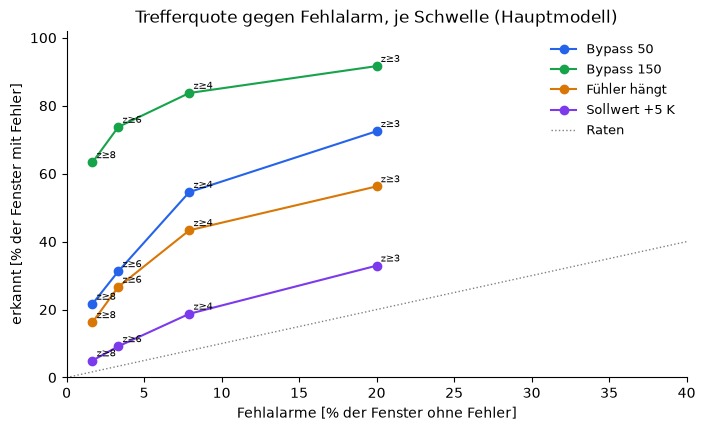

Gewählte Schwelle für den Betrieb: z ≥ 4 (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)


In [83]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for fehler, farbe in zip(FEHLER[1:], ["#2563EB", "#16A34A", "#D97706", "#7C3AED"]):
    ax.plot(inj.loc["ohne"] * 100, inj.loc[fehler] * 100, "o-", color=farbe, label=fehler)
    for s in SCHWELLEN:
        ax.annotate(f"z≥{s}", (inj.loc["ohne", s] * 100, inj.loc[fehler, s] * 100), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
ax.plot([0, 100], [0, 100], ":", color="grey", lw=1, label="Raten")
ax.set_xlim(0, max(40, inj.loc["ohne"].max() * 110))
ax.set_ylim(0, 102)
ax.set_xlabel("Fehlalarme [% der Fenster ohne Fehler]")
ax.set_ylabel("erkannt [% der Fenster mit Fehler]")
ax.set_title("Trefferquote gegen Fehlalarm, je Schwelle (Hauptmodell)")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

SCHWELLE = min([s for s in SCHWELLEN if inj.loc["ohne", s] <= 0.10], default=max(SCHWELLEN))
print(f"Gewählte Schwelle für den Betrieb: z ≥ {SCHWELLE} (kleinste mit höchstens 10 % Fehlalarmen in 8 Tagen)")

- Jede Linie ist ein Fehler, jeder Punkt eine Schwelle: x = Fehlalarme, y = Treffer. Gut ist oben links.
- Eine niedrigere Schwelle bringt immer mehr Treffer und mehr Fehlalarme. Fair vergleichen lässt sich nur bei gleicher Fehlalarmrate.
- Für den Betrieb gilt die kleinste Schwelle, bei der höchstens jedes zehnte Fenster ohne Fehler einen Fehlalarm hat.

- Gewählt wird z ≥ 4 mit 8 % Fehlalarmen in der Testzeit; bei z ≥ 3 wären es 20 %. (Ein Zwischenlauf mit alten Gewichten und neu gezogenen Validierungswochen ergab z ≥ 6, weil das Netz einen Teil der Validierungstage schon im Training gesehen hatte. Mit neu trainierten Netzen passt es wieder.)
- Bei dieser Schwelle findet der Wächter innerhalb von acht Tagen: Bypass 150 l/h zu 84 %, Bypass 50 l/h zu 55 %, hängenden Fühler zu 43 %, um 5 K verstellten Sollwert zu 19 %.
- Der Sollwert bleibt schwach. 5 K liegen im Bereich der normalen Schwankung von Tag zu Tag, und ab dem zweiten Tag gewöhnt sich das Netz über die Vorgeschichte an den höheren Rücklauf.
- Zum Vergleich die erste Fassung (alle HAST, ohne Faktor, z ≥ 3): 5 % Fehlalarme; Bypass 150 l/h 90 %, Bypass 50 l/h 49 %, Fühler 38 %, Sollwert 21 %. Bei etwas höherer Fehlalarmrate (8 statt 5 %) findet der Wächter also ähnlich viel.

In [84]:
#Dieselbe Prüfung mit dem Vergleichsnetz auf allen HAST, bei der gewählten Schwelle
abw_alle = abweichungen(modelle["alle"], werte, ziel_idx)
abw_alle["abschnitt"] = tage.loc[ziel_idx, "abschnitt"].to_numpy()
kal_alle, faktor_alle = kalibrieren(abw_alle)
inj_alle = injektion(modelle["alle"], kal_alle, faktor_alle)
pd.DataFrame({"Hauptmodell (begangene HAST)": inj[SCHWELLE], "Vergleich (alle HAST)": inj_alle[SCHWELLE]}).round(2)

,Hauptmodell (begangene HAST),Vergleich (alle HAST)
Fehler,,
ohne,0.08,0.13
Bypass 50,0.55,0.56
Bypass 150,0.84,0.85
Fühler hängt,0.43,0.48
Sollwert +5 K,0.19,0.28


- Dieselbe Fehlerprüfung mit dem Netz auf allen HAST, mit gleicher Schwelle und gleichen Testfenstern. So zeigt sich, ob die Vorgabe den Wächter schwächt.

- Das Netz auf allen HAST findet etwas mehr (Bypass 50 l/h: 56 statt 55 %, Fühler: 48 statt 43 %, Sollwert: 28 statt 19 %), schlägt aber auch öfter falsch an (13 statt 8 % Fehlalarme).
- Mehr Treffer bei mehr Fehlalarmen sind kein klarer Vorteil. Bei den eingerechneten Fehlern schwächt die Vorgabe den Wächter nicht nennenswert.

## 10 Alarme zählen wie beim Normalverhaltensmodell

- Eine Station, die nach einer Veränderung zwei Wochen lang warnt, hat ein Problem, nicht vierzehn.
- Das Normalverhaltensmodell zählt deshalb einen Alarm je Veränderung. Hier genauso: Ein Alarm ist der erste Warntag nach mindestens sieben Tagen ohne Warnung.
- So lässt sich die Alarmmenge in derselben Einheit messen wie beim Normalverhaltensmodell: Alarme je Station und Jahr.

In [85]:
RUHE = 7
betrieb = tag_abw[tag_abw["zaehler"].isin(kal.index)].copy()
betrieb["warnung"] = warnungen(betrieb, SCHWELLE)
vorige_warnung = betrieb["tag"].where(betrieb["warnung"]).groupby(betrieb["zaehler"]).transform(lambda s: s.ffill().shift(1))
betrieb["alarm"] = betrieb["warnung"] & ((betrieb["tag"] - vorige_warnung).dt.days.isna() | ((betrieb["tag"] - vorige_warnung).dt.days > RUHE))

ueberwacht = betrieb[betrieb["abschnitt"].isin(["Test (Sommer 2024)", "nach der Begehung"])]
jahre = ueberwacht.groupby("zaehler")["tag"].agg(lambda s: (s.max() - s.min()).days + 1).sum() / 365.25
rate = pd.DataFrame({
    "Warntage": ueberwacht.groupby("heiztag")["warnung"].sum(),
    "Alarme": ueberwacht.groupby("heiztag")["alarm"].sum(),
}).rename(index={True: "Heiztage", False: "warme Tage"})
print(f"Überwacht: {ueberwacht['zaehler'].nunique()} Zähler, zusammen {jahre:.0f} Stationsjahre (Juni 2024 bis Datenende)")
print(f"Alarme insgesamt: {ueberwacht['alarm'].sum()} = {ueberwacht['alarm'].sum() / jahre:.1f} je Station und Jahr "
      f"(Warntage: {ueberwacht['warnung'].sum()})")
rate

Überwacht: 82 Zähler, zusammen 92 Stationsjahre (Juni 2024 bis Datenende)
Alarme insgesamt: 265 = 2.9 je Station und Jahr (Warntage: 1592)


,Warntage,Alarme
heiztag,,
warme Tage,511,99
Heiztage,1081,166


- Markiert je Station den ersten Warntag nach mindestens sieben ruhigen Tagen als Alarm.
- Zählt die Stationsjahre der Überwachung (Testzeit und Betrieb danach) und daraus die Alarme je Station und Jahr, getrennt nach Heiztagen und warmen Tagen.

- 265 Alarme in 92 Stationsjahren (82 Zähler), also 2,9 je Station und Jahr. Das Normalverhaltensmodell kommt auf 3,6, der Kennlinienmonitor auf knapp 5. Das ist dieselbe Größenordnung und für einen Betrieb handhabbar.
- 166 der 265 Alarme fallen auf Heiztage, 99 auf warme Tage. Den Sommer überwacht nur dieser Wächter; das Normalverhaltensmodell rechnet nur Heiztage.
- Ein Alarm entsteht im Mittel aus 6 Warntagen (1.592 Warntage). Deshalb zählt man Alarme, nicht Warntage.

## 11 Echte Begehungen: Merkt der Wächter die Veränderung?

- Bei vielen Begehungen wurde etwas verstellt oder getauscht. Ein guter Wächter sollte das als Veränderung bemerken, denn er kennt nur das Verhalten vorher.
- Erster Blick: Anteil der Stationen mit Alarm in den 14 Tagen nach der Begehung, verglichen mit nie begangenen Stationen in denselben Kalenderwochen.
- Die ausführliche Prüfung mit dem Verfahren aus Notebook 18 und derselben Kontrollgruppe steht in [Notebook 30](30_waechtervergleich.ipynb).

In [86]:
NACH = 14
begangen_tab = labels.dropna(subset=["erste_begehung"])
begangen_tab = begangen_tab[begangen_tab.index.isin(kal.index)]
nie = sorted(set(kal.index) - set(labels.index))
daten_pool = begangen_tab["erste_begehung"].to_numpy()


def alarm_im_fenster(zaehler, von):
    t = betrieb[(betrieb["zaehler"] == zaehler) & (betrieb["tag"] >= von) & (betrieb["tag"] < von + pd.Timedelta(days=NACH))]
    return t["alarm"].any() if len(t) >= 7 else np.nan


zeilen = [{"Gruppe": "begangen", "zaehler": z, "ventil": begangen_tab.loc[z, "ventil"],
           "alarm": alarm_im_fenster(z, begangen_tab.loc[z, "erste_begehung"])} for z in begangen_tab.index]
rng = np.random.default_rng(SEED)
for z in nie:
    for datum in rng.choice(daten_pool, size=3, replace=False):
        zeilen.append({"Gruppe": "nie begangen (Vergleich)", "zaehler": z, "ventil": np.nan, "alarm": alarm_im_fenster(z, pd.Timestamp(datum))})
nach_begehung = pd.DataFrame(zeilen).dropna(subset=["alarm"])
nach_begehung["alarm"] = nach_begehung["alarm"].astype(bool)
nach_begehung["Teilgruppe"] = np.where(nach_begehung["ventil"] == True, "begangen, Ventil getauscht",
                                       np.where(nach_begehung["Gruppe"] == "begangen", "begangen, anderer Eingriff", "nie begangen (Vergleich)"))
nach_begehung.groupby("Teilgruppe")["alarm"].agg(Fenster="size", mit_Alarm="sum", Anteil="mean").round(2)

,Fenster,mit_Alarm,Anteil
Teilgruppe,,,
"begangen, Ventil getauscht",9,1,0.11
"begangen, anderer Eingriff",29,5,0.17
nie begangen (Vergleich),78,10,0.13


- Je begangener Station: Gab es in den 14 Tagen ab der Begehung einen Alarm? Fenster mit weniger als 7 vorhergesagten Tagen zählen nicht.
- Vergleich: Für jede nie begangene Station werden drei echte Begehungsdaten anderer Stationen gezogen und dieselbe Frage gestellt. So stimmen Jahreszeit und Wetter überein.

- Nach einer Begehung gibt es in 14 Tagen bei 11 bis 17 % der begangenen Stationen einen Alarm (Ventil getauscht: 1 von 9, anderer Eingriff: 5 von 29). Bei nie begangenen Stationen in denselben Wochen sind es 13 % (10 von 78 Fenstern). Schon dieser erste Blick zeigt keinen Vorsprung.
- In der vorigen Fassung (96 Zähler, nur 67 davon überwacht) sah es besser aus: 24 bis 29 % gegen 8 %.
- Notebook 30 zeigt: Dieses LSTM schlägt an begangenen Stationen generell öfter an, auch ohne Begehung im Fenster (37 % gegen 8 % in 14 Tagen). Ein möglicher Grund ist die Vorgabe: Die begangenen Stationen hat das Netz gelernt, dort ist seine normale Schwankung kleiner.
- Mit der Prüfung und Kontrollgruppe aus Notebook 18 gibt es ebenfalls keinen Vorsprung (18 % gegen 17 % in 14 Tagen).

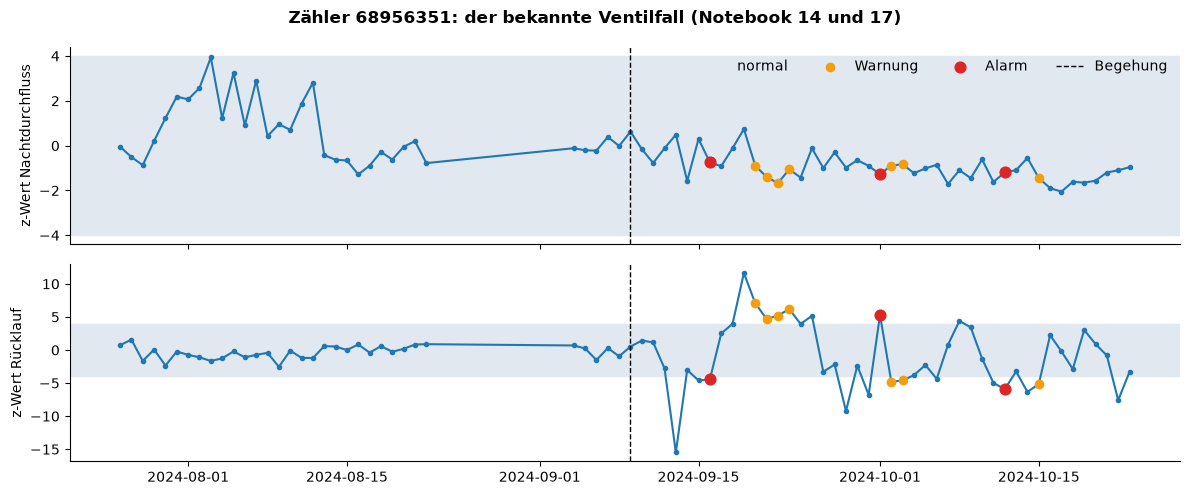

Begehung 09.09.2024, erster Alarm danach: 16.09.2024 (7 Tage)


In [87]:
FALL = 68956351
if FALL in begangen_tab.index:
    datum = begangen_tab.loc[FALL, "erste_begehung"]
    t = betrieb[(betrieb["zaehler"] == FALL) & (betrieb["tag"] >= datum - pd.Timedelta(days=45)) & (betrieb["tag"] < datum + pd.Timedelta(days=45))]
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    for ax, spalte, titel in ((axes[0], "z_fluss", "z-Wert Nachtdurchfluss"), (axes[1], "z_rl", "z-Wert Rücklauf")):
        ax.plot(t["tag"], t[spalte], "o-", ms=3)
        ax.axhspan(-SCHWELLE, SCHWELLE, color="#E2E8F0", label="normal")
        ax.scatter(t.loc[t["warnung"], "tag"], t.loc[t["warnung"], spalte], color="#F59E0B", zorder=3, label="Warnung")
        ax.scatter(t.loc[t["alarm"], "tag"], t.loc[t["alarm"], spalte], color="#DC2626", s=60, zorder=4, label="Alarm")
        ax.axvline(datum, color="black", ls="--", lw=1, label="Begehung")
        ax.set_ylabel(titel)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, ncol=4)
    fig.suptitle(f"Zähler {FALL}: der bekannte Ventilfall (Notebook 14 und 17)", fontweight="bold")
    fig.tight_layout()
    plt.show()
    erste = t[(t["tag"] >= datum) & t["alarm"]]["tag"].min()
    print(f"Begehung {datum:%d.%m.%Y}, erster Alarm danach: {erste:%d.%m.%Y} ({(erste - datum).days} Tage)")

- Zeigt für den bekannten Ventilfall 68956351 die beiden z-Werte rund um die Begehung. Grau ist der Normalbereich, gelb sind Warntage, rot ist der Alarm.
- Der Fall ist schon aus dem Kennlinienmonitor (Notebook 13) und dem Normalverhaltensmodell (Notebook 18) bekannt.

- Vor der Begehung am 09.09.2024 liegt alles im Normalbereich, obwohl das Ventil seit Jahren offen stand. Der Wächter vergleicht die Station mit sich selbst; das offene Ventil war ihr Normalzustand.
- Nach dem Tausch fällt der Rücklauf weit unter die Erwartung, am vierten Tag um 15 Streuungen. Die Station kühlt plötzlich viel besser aus, wie es ein neues Ventil bewirken soll.
- Der erste Alarm kommt nach 7 Tagen. Der Ausschlag am vierten Tag war ein einzelner Tag, die Warnregel verlangt zwei Tage hintereinander.
- Beim Nachtdurchfluss ändert sich weniger. Im September wird schon wieder geheizt, nachts fließt also ohnehin Wasser.

## 12 Haus oder Netz?

- Warnen viele Stationen am selben Tag, liegt es selten an jedem einzelnen Haus, eher am Netz (Vorlauftemperatur, Pumpen, Umstellung in der Heizzentrale).
- Der Wächter zählt deshalb, wie viele Stationen am selben Tag warnen.
- Zum Vergleich steht dabei dieselbe Zählung ohne Faktor je Jahreszeit.

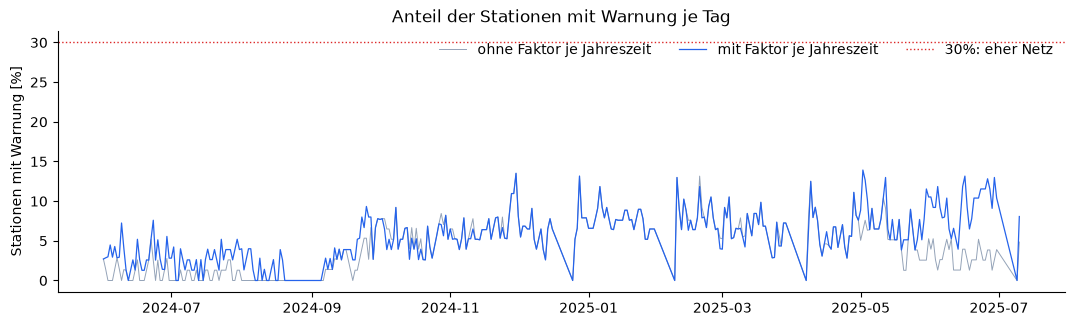

Median je Monat (Anteil der Stationen mit Warnung, %):
tag                       2024-06  2024-07  2024-08  2024-09  2024-10  2024-11  2024-12  2025-01  2025-02  2025-03  2025-04  2025-05  2025-06  2025-07
mit Faktor je Jahreszeit      2.8      2.6      1.3      3.9      5.2      5.9      6.5      7.6      7.9      6.6      5.9      6.5      9.8      4.0
ohne Faktor                   1.3      0.0      0.0      2.7      5.6      6.4      6.5      7.6      7.9      6.8      5.6      5.2      2.6      2.4


zaehler,begangene HAST,nie begangen
tag,,
2024Q2,4.0,1.5
2024Q3,3.0,2.6
2024Q4,3.5,10.4
2025Q1,4.9,11.5
2025Q2,6.0,11.2
2025Q3,0.6,6.5


In [88]:
ohne_faktor = z_werte(tag_abw[["zaehler", "tag", "heiztag", "res_rl", "res_fluss_nacht", "abschnitt"]], kal, None)
ohne_faktor["warnung"] = warnungen(ohne_faktor, SCHWELLE)
vergleich = pd.DataFrame({
    "mit Faktor je Jahreszeit": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag")["warnung"].mean(),
    "ohne Faktor": ohne_faktor[ohne_faktor["zaehler"].isin(kal.index) & (ohne_faktor["abschnitt"] != "Training")].groupby("tag")["warnung"].mean(),
    "Stationen": betrieb[betrieb["abschnitt"] != "Training"].groupby("tag").size(),
})
vergleich = vergleich[(vergleich["Stationen"] >= 20) & (vergleich.index >= LERNEN_BIS)]
NETZ_ANTEIL = 0.3
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(vergleich.index, vergleich["ohne Faktor"] * 100, lw=0.7, color="#94A3B8", label="ohne Faktor je Jahreszeit")
ax.plot(vergleich.index, vergleich["mit Faktor je Jahreszeit"] * 100, lw=0.9, color="#2563EB", label="mit Faktor je Jahreszeit")
ax.axhline(NETZ_ANTEIL * 100, color="#DC2626", ls=":", lw=1, label=f"{NETZ_ANTEIL:.0%}: eher Netz")
ax.set_ylabel("Stationen mit Warnung [%]")
ax.set_title("Anteil der Stationen mit Warnung je Tag")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
monat = vergleich[["mit Faktor je Jahreszeit", "ohne Faktor"]].groupby(vergleich.index.to_period("M")).median()
print("Median je Monat (Anteil der Stationen mit Warnung, %):")
print((monat * 100).round(1).T.to_string())

#Wer warnt? Begangene Stationen (nach der Begehung verändert) gegen nie begangene
spaeter = betrieb[betrieb["tag"] >= LERNEN_BIS]
gruppe = spaeter["zaehler"].isin(labels.index).map({True: "begangene HAST", False: "nie begangen"})
(spaeter.groupby([spaeter["tag"].dt.to_period("Q"), gruppe])["warnung"].mean().unstack() * 100).round(1).dropna()

- Zählt je Kalendertag den Anteil der Stationen mit Warnung, mit und ohne Faktor je Jahreszeit. Nur Tage mit mindestens 20 vorhergesagten Stationen.
- Tage, an denen mindestens 30 % der Stationen gleichzeitig warnen, gelten als Netz-Tage. Eine Warnung an einem solchen Tag geht an den Netzbetreiber, nicht an den Hauseigentümer.
- Die letzte Tabelle zeigt je Quartal, an wie viel Prozent ihrer Tage begangene und nie begangene Stationen warnen.

- An keinem Tag warnen 30 % der Stationen gleichzeitig, der höchste Wert liegt bei 14 %. Ein Netzereignis, das viele Stationen zugleich trifft, gibt es in diesen Daten nicht.
- Der Faktor je Jahreszeit verschiebt wenig. Im Sommer gibt es mehr Warnungen (Juni/Juli 2024: 2,6 bis 2,8 % statt 0 bis 1,3 %, Juni 2025: 9,8 % statt 2,6 %), im Winter ändert sich fast nichts (Dezember 6,5 % mit und ohne).
- Im Winter 24/25 warnen begangene Stationen an 3 bis 6 % ihrer Tage, nie begangene an 10 bis 12 %. In der vorigen Fassung war es umgekehrt (7 bis 11 % gegen 1 bis 3 %).
  - Der Unterschied kommt fast nur von vier nie begangenen Stationen, die erst in dieser Fassung überwacht werden (72135480, 72167793, 80956410, 80912185). Drei davon warnen an mehr als zwei Dritteln ihrer Wintertage.
  - Ihre normale Schwankung stammt aus nur 14 Validierungstagen (bei 72135480 aus 44), alle aus dem Winter 23/24. Zwei von ihnen hatten im Sommer 2024 nachts 371 bzw. 801 l/h Durchfluss, also das Ventilbild.
  - Ohne diese vier bleibt das Bild der vorigen Fassung: übrige nie begangene unter 1 % ihrer Wintertage, begangene etwa 5 %. Die begangenen Stationen arbeiten nach dem Eingriff anders als in der Lernzeit, und der Wächter meldet das zu Recht.
- Für den Betrieb: Nach einem bekannten Eingriff muss der Wächter die Station neu kennenlernen (neue normale Schwankung, im besten Fall nachtrainiert), sonst meldet er dieselbe Veränderung immer wieder. Und eine Station sollte erst überwacht werden, wenn ihre normale Schwankung aus genug Tagen beider Jahreszeiten stammt; mindestens 10 Validierungstage reichen dafür nicht.

## 13 Ergebnis speichern

- Speichert die Tagesergebnisse aller überwachten Zähler nach `data/processed/prognose_tage.csv`.

In [89]:
aus = betrieb[["zaehler", "tag", "abschnitt", "heiztag", "res_rl", "res_fluss_nacht", "z_rl", "z_fluss", "warnung", "alarm"]].copy()
z_alle = z_werte(abw_alle, kal_alle, faktor_alle)       #dasselbe für das Netz auf allen HAST (Vergleich in NB 30)
aus["z_rl_alle"] = z_alle["z_rl"].reindex(aus.index)
aus["z_fluss_alle"] = z_alle["z_fluss"].reindex(aus.index)
aus.to_csv(PROCESSED / "prognose_tage.csv", index=False)
print(f"prognose_tage.csv: {len(aus):,} Zähler-Tage von {aus['zaehler'].nunique()} Zählern; Schwelle z ≥ {SCHWELLE}")
aus.head()

prognose_tage.csv: 58,524 Zähler-Tage von 87 Zählern; Schwelle z ≥ 4


,zaehler,tag,abschnitt,heiztag,res_rl,res_fluss_nacht,z_rl,z_fluss,warnung,alarm,z_rl_alle,z_fluss_alle
7,53198226,2022-11-20,Validierung,True,6.942938,-0.825770,2.091182,0.599025,False,False,2.908124,0.836262
8,53198226,2022-11-21,Training,True,-7.883430,-53.549826,-1.795933,-0.180650,False,False,-2.058590,0.291764
9,53198226,2022-11-22,Training,True,-0.004867,-10.290036,0.269636,0.459069,False,False,0.499846,0.302638
10,53198226,2022-11-23,Training,True,-3.938563,24.699377,-0.761684,0.976487,False,False,0.146984,1.522786
11,53198226,2022-11-24,Training,True,-5.439882,31.999767,-1.155294,1.084443,False,False,-0.462620,1.675422


- `prognose_tage.csv`: 58.524 Zähler-Tage von 87 Zählern mit Abweichung, z-Werten, Warnung und Alarm, Schwelle z ≥ 4.
- Notebook 29 fasst die Tage vor der Begehung je Station zusammen. Notebook 30 vergleicht die Alarme mit dem Normalverhaltensmodell.
- `z_rl_alle` und `z_fluss_alle` sind die z-Werte des Vergleichsnetzes auf allen HAST. Damit prüft Notebook 30, ob die Vorgabe den Vergleich verändert.

## Zusammenfassung & Bewertung

**Ergebnis**
- Vorversuche: Das Mittel der letzten 7 Tage ist die beste einfache Erwartung (U-Form von 1 bis 30 Tagen). Ein LSTM mit 7 Tagen Eingabe ist auf der Validierung am besten. Das Wetter von morgen ändert die Vorhersage kaum. Ein einfacher Wächter ohne Netz bemerkt an Begehungen nur den Eingriff selbst, nicht die Veränderung danach.
- Ein Encoder-Decoder-LSTM (35.458 Gewichte, 24 Sekunden Training auf der GPU) sagt für 87 Stationen jeden Tag Rücklauf und Durchfluss vorher. Gelernt nach Vorgabe nur auf begangenen HAST, ein Netz auf allen HAST dient zum Vergleich.
- Warnregel: z ≥ 4 an zwei Tagen hintereinander, mit Faktor je Jahreszeit. Ein Alarm je Veränderung, gezählt wie beim Normalverhaltensmodell.
- Bei eingerechneten Fehlern erkannt (8 % Fehlalarme): Bypass 150 l/h zu 84 %, Bypass 50 l/h zu 55 %, hängender Fühler zu 43 %, Sollwert +5 K zu 19 %.
- Der Wächter sucht neue Fehler, das ganze Jahr und auf Stundenbasis. Fehler, die es schon immer gab, sieht er nicht (Beispiel Ventilfall 68956351). Dafür sind Notebook 27 und 29 da.
- `prognose_tage.csv` geht an Notebook 29 und 30.

**Belastbar**
- Die Rücklauf-Vorhersage ist deutlich besser als einfache Regeln: 4,3 K gegen 6,2 K („wie gestern“), auch bei nie gesehenen Stationen besser als „wie gestern“.
- Ein plötzlich offenes Ventil (Bypass 150 l/h) findet der Wächter meist innerhalb von acht Tagen, bei 8 % Fehlalarmen im Sommer.
- Die Alarmmenge ist handhabbar: 2,9 je Station und Jahr (Normalverhaltensmodell: 3,6), in derselben Einheit gemessen.
- Wiederholbar: Ein Lauf ohne gespeicherte Gewichte liefert dieselben Zahlen.

**Schwach**
- Hängender Fühler (43 %) und Sollwert +5 K (19 %) werden schlecht erkannt. 5 K liegen in der normalen Schwankung von Tag zu Tag. Dafür sind Vergleiche über Wochen besser geeignet, etwa die Kennlinie mit CUSUM in Notebook 18.
- Bei nie begangenen Stationen ist die Durchfluss-Vorhersage schlechter als „wie gestern“ (208 gegen 142 l/h). Das ist der Preis der Vorgabe.
- Alarme nach echten Begehungen: 11 bis 17 % gegen 13 % bei nie begangenen Stationen, auch mit der Prüfung aus Notebook 18 kein Vorsprung (Notebook 30). Eine Begehung verschiebt den Betrieb nur um etwa eine halbe Streuung. Das Normalverhaltensmodell bemerkt das bei gleich vielen Alarmen in 30 von 43 Fällen, dieses LSTM in 16.
- Die Winterwarnungen kommen von Stationen, die sich nach der Begehung verändert haben, und von vier nie begangenen Stationen mit zu wenigen Lerntagen. Haus oder Netz ließ sich nicht prüfen, weil es in den Daten keinen Netz-Tag gibt.

**Offen**
- Für einen Wächter über alle Stationen wäre ein Netz auf allen HAST die bessere Wahl. In Notebook 35 lernt der Wächter deshalb auf allen Stationen, die er überwachen soll.
- Für den Betrieb braucht es ein Neukalibrieren nach jedem bekannten Eingriff und genug Lerntage aus beiden Jahreszeiten, bevor eine Station überwacht wird. Wie viele Tage reichen, ist offen.